# Entrega 1 — Priorizar el despacho de una cuadrilla

**Machine Learning** · Grupos de 4 · 10 % de la calificación final · Vence el **martes 6 de octubre**

**Integrantes**

1. Marcos Devincenzi
2. Facundo Díaz
3. Santiago Alba
4. Domingo Leiva

---

La consigna completa está en `enunciado.pdf`. Este notebook fija **las trece secciones y su orden**; la corrección se hace **contra el enunciado**, no contra el template.

Condiciones de uso:

- Las celdas de texto describen qué se pide en cada sección y **no se eliminan**. Las respuestas escritas se agregan en las celdas marcadas para eso, que pueden extenderse tanto como haga falta.
- Las celdas de código llegan vacías y pueden dividirse en tantas como convenga.
- **El notebook se entrega ejecutado de punta a punta**, con todas las salidas visibles y en el orden en que se generaron. Un notebook sin ejecutar no está entregado.
- Toda celda con aleatoriedad fija su semilla, y la semilla se mantiene igual en todas las comparaciones del notebook: dos resultados que se comparan no pueden diferir por la partición.

**Los datos se construyen uniendo dos fuentes**, y esa construcción es parte del trabajo:

1. El archivo abierto de OSE «Solicitudes y reclamos operativos 2024», que se descarga de <https://datos.ose.com.uy/dataset/reclamos-operativos>. Es un ZIP de unos 10 MB que descomprime a un CSV de unos 114 MB **separado por punto y coma**.
2. `data/entregas_reclamos_complemento.csv`, que aporta la cátedra.

La ruta del archivo descargado se declara **en la celda de configuración de abajo y en ningún otro lado**, de modo que el notebook pueda reproducirse cambiando una sola línea. En Colab, los dos archivos deben subirse o montarse antes de la primera lectura.

### Configuración: importaciones, rutas y semilla

Importar las bibliotecas que el trabajo use, declarar las rutas de los dos archivos y fijar la semilla. Nada de esta celda se evalúa.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_squared_error, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text

warnings.filterwarnings("ignore", message="Found unknown categories")  # una categoría con un solo reclamo
plt.rcParams.update({"figure.figsize": (8, 3.6), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

# Rutas de los archivos: se declaran acá y en ningún otro lado
ARCHIVO_OSE = Path("data/solicitudes_reclamos_operativos_2024.csv")
ARCHIVO_COMPLEMENTO = Path("data/entregas_reclamos_complemento.csv")
ARCHIVO_METADATOS = Path("data/metadatos_ose.csv")

SEMILLA = 42
PLAZO_HORAS = 72
COSTO_FP = 45          # USD: priorizar un reclamo que no iba a superar el plazo
COSTO_FN = 270         # USD: no priorizar un reclamo que sí lo supera
VOLUMEN_ANUAL = 390_000

print("Entorno listo.")

Entorno listo.


## 1. Ingesta, unión y auditoría del conjunto

**Primero, la construcción de la tabla de trabajo.** Documentar cuántas filas trae cada fuente, cuántas sobreviven al filtro, cuántas quedan después de la unión y **qué garantiza que la unión no perdió ni multiplicó registros**. Una unión que cambia el número de filas sin explicación es un error de la sección, no un detalle.

**Después, la auditoría**, antes de ajustar ningún modelo: dimensiones, tipos, resumen descriptivo, distribución de cada variable, valores faltantes por columna y el patrón que siguen, filas repetidas, valores imposibles y cardinalidad de las variables categóricas.

Para **cada** variable con faltantes, diagnosticar el mecanismo —MCAR, MAR o MNAR— y sostener el diagnóstico con el contraste que lo separa de las otras dos alternativas. Cuando el mecanismo no sea diagnosticable con los datos observados, decirlo y explicar por qué. **El tratamiento se deriva del diagnóstico, no al revés.**

**Por último, construir la respuesta binaria** a partir del plazo comprometido, dejando dicho qué se hizo con los registros para los que esa construcción no tiene sentido.

Un hallazgo sin la cifra o el gráfico que lo produce no cuenta como hallazgo.

**Fuentes:** [OSE, solicitudes y reclamos operativos](https://datos.ose.com.uy/dataset/reclamos-operativos), sus metadatos y [complemento de la cátedra](https://github.com/ucudal/Machine-Learning---Ingenieria-en-IA-y-CD/blob/main/data/entregas_reclamos_complemento.csv). Se conserva el CSV original y se verifica su hash para reconocer la versión.

OSE se lee con `;` y UTF-8; el archivo de metadatos usa Windows-1252. Su diccionario utiliza nombres abreviados (`id_ro_m`, `tipo_ro`) que corresponden a `id_reclamo_operativo_m` e `id_tipo_reclamo_operativo` en el CSV. El primero es un hash identificador y el segundo contiene una descripción categórica, no un número ordinal.

La unión debe preservar exactamente los identificadores del complemento. No se supone que una unión sea correcta solo porque el código corre: se contrastan conteos, unicidad, cobertura y cardinalidad.

In [2]:
ose = pd.read_csv(ARCHIVO_OSE, sep=";", encoding="utf-8-sig", dtype={"id_reclamo_operativo_m": str})
complemento = pd.read_csv(ARCHIVO_COMPLEMENTO, dtype={"id_reclamo": str})
metadatos = pd.read_csv(ARCHIVO_METADATOS, sep=";", encoding="cp1252")

print("Diccionario de OSE (metadatos):")
for nombre, descripcion in zip(metadatos["nombre_de_atributo"], metadatos["descripcion"]):
    print(f"  {nombre:26s} {descripcion}")

print(f"\nArchivo de OSE: {len(ose)} filas")
print(f"Complemento:    {len(complemento)} filas")

# Filtrar OSE a los reclamos del complemento y unir por el identificador
filtrado = ose[ose["id_reclamo_operativo_m"].isin(complemento["id_reclamo"])]
tabla = complemento.merge(filtrado, left_on="id_reclamo", right_on="id_reclamo_operativo_m",
                          how="inner", validate="one_to_one")
print(f"OSE filtrado:   {len(filtrado)} filas")
print(f"Tras la unión:  {len(tabla)} filas")

# VERIFICACIÓN — la unión no perdió ni multiplicó reclamos
assert ose["id_reclamo_operativo_m"].is_unique, "hay identificadores repetidos en OSE"
assert complemento["id_reclamo"].is_unique, "hay identificadores repetidos en el complemento"
assert len(filtrado) == len(complemento), "algún reclamo del complemento no está en OSE"
assert len(tabla) == len(complemento), "la unión cambió el número de filas"
print("\nLa unión conserva exactamente los reclamos del complemento, sin perder ni duplicar.")

tabla = tabla.drop(columns="id_reclamo_operativo_m")

Diccionario de OSE (metadatos):
  region                     Región OSE a la que pertenece el departamento.
  departamento               Departamento al que pertenece el reclamo o solicitud operativa.
  fecha_ingreso              Fecha de ingreso de la solicitud o reclamo operativo.
  id_ro_m                    Identificador de la solicitud o reclamo pseudonimizado. El identificador original fue reemplazado por un valor hash irreversible.
  tipo_ro                    Clasificación del reclamo operativo. (ej:'Medidor Hurtado')."
  tipo_complejidad           Clasificación  que refiere a la complejidad para el equipo que resuelve (ej:"'Con corte de pavimento', etc)."
  ausencia_agua              Indica si se reclama por ausencia de agua.
  baja_presion               Indica si se reclama por baja presión.
  inunda                     Indica si se reclama con inundación.
  fecha_resuelto_visita      Fecha de la ultima visita que resolvió el reclamo si el reclamo tuvo una orden de trabajo as

Dimensiones: 3964 filas x 21 columnas

Tipos de cada columna:
id_reclamo                       str
distancia_centro_km          float64
conexiones_afectadas         float64
calificacion_atencion        float64
año                            int64
region                           str
departamento                     str
fecha_ingreso                    str
id_tipo_reclamo_operativo        str
tipo_complejidad                 str
ausencia_agua                    str
baja_presion                     str
inunda                           str
fecha_resuelto_visita            str
fecha_resuelto_sistema           str
tiempo_resolucion_minutos      int64
id_centro_tecnico              int64
estado_resuelto                  str
tipo_orden                       str
grupo_orden                      str
fecha_foto                       str

Resumen de las numéricas:
                            count     mean        std        min      25%      50%      75%       max
distancia_centro_km        3964.

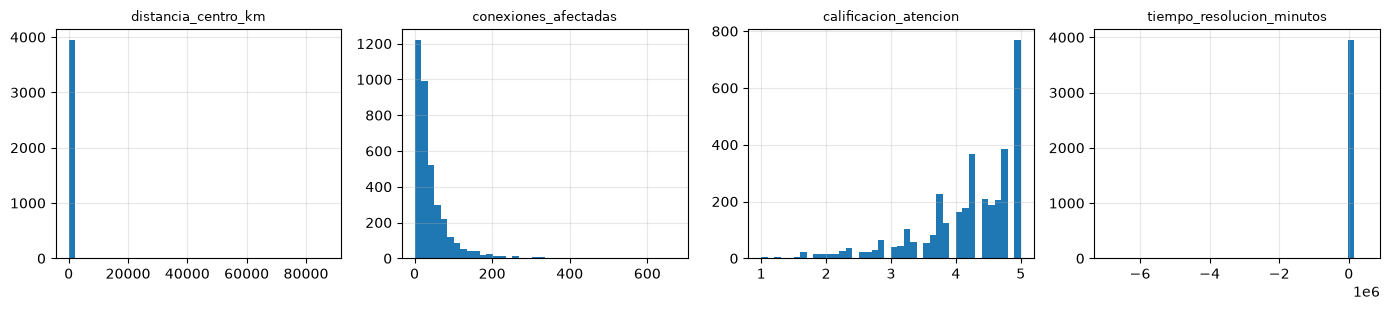


region:
region
MDEO             1740
CENTRO            837
LITORAL NORTE     354
LITORAL SUR       292
UGD               288
NORESTE           278
SURESTE           175

departamento:
departamento
MONTEVIDEO        1740
CANELONES          680
MALDONADO          288
SALTO              149
SAN JOSE           111
COLONIA            110
RIVERA             109
ROCHA               99
PAYSANDU            99
TACUAREMBO          98
FLORIDA             81
DURAZNO             76
ARTIGAS             74
CERRO LARGO         71
SORIANO             54
LAVALLEJA           42
TREINTA Y TRES      34
RIO NEGRO           32
FLORES              17

id_tipo_reclamo_operativo:
id_tipo_reclamo_operativo
 RP  Denuncia de Pérdida                                          1714
 PA  Problema de Abastecimiento (falta de agua o poca presion)    1625
 RS  Saneamiento del Interior                                      239
 SV  Solicitudes Varias                                            168
 RS Reposición y Señalizaci

In [3]:
print(f"Dimensiones: {tabla.shape[0]} filas x {tabla.shape[1]} columnas\n")
print("Tipos de cada columna:")
print(tabla.dtypes.to_string())

print("\nResumen de las numéricas:")
print(tabla.describe().T.round(2))

print("\nFaltantes por columna:")
print(tabla.isna().sum().loc[lambda s: s > 0].to_string())

print("\nCardinalidad de las categóricas:")
print(tabla.select_dtypes(exclude="number").nunique().sort_values().to_string())

# Distribución de las numéricas
NUM_CRUDAS = ["distancia_centro_km", "conexiones_afectadas", "calificacion_atencion",
              "tiempo_resolucion_minutos"]
fig, ejes = plt.subplots(1, 4, figsize=(14, 3.2))
for eje, col in zip(ejes, NUM_CRUDAS):
    eje.hist(tabla[col].dropna(), bins=40)
    eje.set_title(col, fontsize=9)
plt.tight_layout()
plt.show()

# Distribución de las categóricas de baja cardinalidad
for col in ["region", "departamento", "id_tipo_reclamo_operativo", "tipo_complejidad",
            "ausencia_agua", "baja_presion", "inunda", "estado_resuelto", "grupo_orden"]:
    print(f"\n{col}:")
    print(tabla[col].value_counts().to_string())

# Años de las fechas: 1900 es el código de "sin fecha" de los metadatos
print()
for col in ["fecha_ingreso", "fecha_resuelto_visita", "fecha_resuelto_sistema"]:
    años = pd.to_datetime(tabla[col], format="%Y/%m/%d %H:%M").dt.year
    print(f"{col}: {años.value_counts().to_dict()}")

In [4]:
minutos = tabla["tiempo_resolucion_minutos"]
print(f"tiempo = -1 (código de 'sin dato'): {(minutos == -1).sum()}")
print(f"otros tiempos negativos (imposibles): {(minutos < -1).sum()}")
negativos_h = minutos[minutos < -1] / 60
print(f"   de esos, entre -24 h y 0: {(negativos_h > -24).sum()}  (mediana {negativos_h.median():.1f} h)")
print(f"tiempo = 0: {(minutos == 0).sum()}")
print(f"centro técnico = -1: {(tabla['id_centro_tecnico'] == -1).sum()}")
print(f"tipo_orden = 'SIN DATOS': {tabla['tipo_orden'].isin(['SIN DATOS', 'S/DATOS']).sum()}")

copias = tabla.drop(columns="id_reclamo").duplicated()
print(f"filas repetidas (idénticas salvo el id): {copias.sum()}")
print(f"regiones por departamento (máximo): {tabla.groupby('departamento')['region'].nunique().max()}")

# Distancias imposibles: Uruguay mide unos 600 km de punta a punta
grandes = tabla["distancia_centro_km"] > 1000
print(f"\ndistancias mayores a 1000 km: {grandes.sum()} (máximo {tabla['distancia_centro_km'].max():,.0f})")
mediana_depto = tabla[~grandes].groupby("departamento")["distancia_centro_km"].median()
revision = tabla.loc[grandes, ["departamento", "distancia_centro_km"]].copy()
revision["si_eran_metros_km"] = revision["distancia_centro_km"] / 1000
revision["mediana_del_depto_km"] = revision["departamento"].map(mediana_depto)
print(revision.round(2).to_string())

tiempo = -1 (código de 'sin dato'): 10
otros tiempos negativos (imposibles): 321
   de esos, entre -24 h y 0: 291  (mediana -2.4 h)
tiempo = 0: 3
centro técnico = -1: 319
tipo_orden = 'SIN DATOS': 319
filas repetidas (idénticas salvo el id): 32
regiones por departamento (máximo): 1

distancias mayores a 1000 km: 21 (máximo 87,510)
     departamento  distancia_centro_km  si_eran_metros_km  mediana_del_depto_km
4           SALTO              65360.0              65.36                 57.62
21     MONTEVIDEO               6620.0               6.62                  6.99
27       PAYSANDU              39800.0              39.80                 49.94
158    MONTEVIDEO               5130.0               5.13                  6.99
189     LAVALLEJA              49790.0              49.79                 56.91
198     CANELONES              53550.0              53.55                 51.84
406     CANELONES              71420.0              71.42                 51.84
534     CANELONES          

**Decisiones de dominio antes de particionar.** Se excluyen del aprendizaje supervisado todos los tiempos negativos, incluido el centinela `-1`: convertirlos a cero o imputar el objetivo crearía etiquetas que no conocemos. No se reemplazan por la demora hasta el cierre en el sistema, porque los metadatos dicen que ese registro puede ser posterior a la resolución real. Los tres ceros se conservan: una demora nula a resolución de minutos puede representar atención inmediata; no hay evidencia suficiente para imputarle otra demora.

Las distancias superiores a 1.000 km se declaran inválidas para este ejercicio local y se convierten a faltantes. Es una regla fija de plausibilidad, no un percentil aprendido. Se descarta dividir por 1.000 aunque sea compatible con una mezcla de metros y kilómetros: no tenemos confirmación del generador del complemento. Se conservan los valores de 400 km como extremos plausibles; no se eliminan por ser atípicos. El corte es una decisión que debe verificarse con la cátedra, no un máximo oficial de OSE.

Se elimina una copia de registros idénticos en **todas** las columnas no identificadoras, antes de particionar. Es una regla conservadora frente a posible duplicación de la tabla didáctica; diferentes reclamos reales también podrían coincidir. Se deja visible cuántos se excluyen y se reconoce ese límite. No se eliminan casos solo por tener el mismo vector de entradas, porque pueden ser reclamos diferentes.


reclamos válidos: 3604  (se quitaron 32 copias y 331 tiempos negativos)
prevalencia de incumplimiento: 0.1609
prevalencia si los negativos se etiquetaran 0: 0.1479

tiempo de resolución: media 66.6 h · mediana 18.7 h · máximo 8,731 h · asimetría 16.48


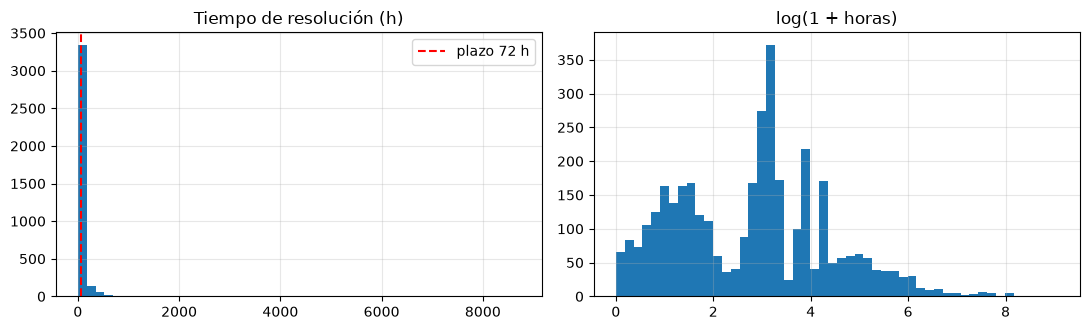

--- conexiones_afectadas: 231 faltantes (6.4 %)
    contra departamento               chi2 =   23.22   p = 0.1822
    contra id_tipo_reclamo_operativo  chi2 =   25.81   p = 0.0011
    contra tipo_complejidad           chi2 =    7.10   p = 0.1307
    contra ausencia_agua              chi2 =    5.85   p = 0.0156
    contra distancia_centro_km        mediana presente   27.8 · ausente   35.9   p = 0.0034
    contra tiempo_horas               mediana presente   18.4 · ausente   21.0   p = 0.0102
--- calificacion_atencion: 434 faltantes (12.0 %)
    contra departamento               chi2 =   20.13   p = 0.3254
    contra id_tipo_reclamo_operativo  chi2 =   23.77   p = 0.0025
    contra tipo_complejidad           chi2 =    4.42   p = 0.3516
    contra ausencia_agua              chi2 =   29.55   p = 0.0000
    contra distancia_centro_km        mediana presente   29.0 · ausente   26.9   p = 0.0153
    contra tiempo_horas               mediana presente   17.3 · ausente   49.7   p = 0.0000
--- id

In [5]:
datos = tabla.copy()

# 1. Códigos de "sin dato" de los metadatos -> faltante
for col in ["fecha_ingreso", "fecha_resuelto_visita", "fecha_resuelto_sistema"]:
    datos[col] = pd.to_datetime(datos[col], format="%Y/%m/%d %H:%M")
    datos.loc[datos[col].dt.year == 1900, col] = pd.NaT
datos["id_centro_tecnico"] = datos["id_centro_tecnico"].replace(-1, np.nan)
for col in ["estado_resuelto", "tipo_orden", "grupo_orden"]:
    datos[col] = datos[col].replace(["SIN DATOS", "S/DATOS"], np.nan)

# 2. Distancias cargadas en metros -> kilómetros
datos.loc[grandes, "distancia_centro_km"] = datos.loc[grandes, "distancia_centro_km"] / 1000

# 3. Copias exactas
datos = datos[~copias]

# 4. Respuesta en horas; los tiempos negativos no se pueden etiquetar y se excluyen
datos["tiempo_horas"] = datos["tiempo_resolucion_minutos"] / 60
datos = datos[datos["tiempo_horas"] >= 0].reset_index(drop=True)
datos["incumple"] = (datos["tiempo_horas"] > PLAZO_HORAS).astype(int)

print(f"reclamos válidos: {len(datos)}  (se quitaron {copias.sum()} copias y {(minutos < 0).sum()} tiempos negativos)")
print(f"prevalencia de incumplimiento: {datos['incumple'].mean():.4f}")

# Sensibilidad: qué prevalencia habría si los negativos contaran como "no incumple"
alternativa = minutos[~copias & (minutos != -1)].clip(lower=0) / 60
print(f"prevalencia si los negativos se etiquetaran 0: {(alternativa > PLAZO_HORAS).mean():.4f}")

horas = datos["tiempo_horas"]
print(f"\ntiempo de resolución: media {horas.mean():.1f} h · mediana {horas.median():.1f} h · "
      f"máximo {horas.max():,.0f} h · asimetría {horas.skew():.2f}")

fig, (izq, der) = plt.subplots(1, 2, figsize=(11, 3.4))
izq.hist(horas, bins=50)
izq.axvline(PLAZO_HORAS, color="red", ls="--", label="plazo 72 h")
izq.set_title("Tiempo de resolución (h)")
izq.legend()
der.hist(np.log1p(horas), bins=50)
der.set_title("log(1 + horas)")
plt.tight_layout()
plt.show()

# Como en el lab 11: chi-cuadrado contra categóricas y test t contra numéricas.
# El tiempo se compara en log por la cola larga; se usa solo para diagnosticar, nunca como entrada.
for col in ["conexiones_afectadas", "calificacion_atencion", "id_centro_tecnico"]:
    falta = datos[col].isna()
    print(f"--- {col}: {falta.sum()} faltantes ({100 * falta.mean():.1f} %)")
    for grupo in ["departamento", "id_tipo_reclamo_operativo", "tipo_complejidad", "ausencia_agua"]:
        chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(datos[grupo], falta))
        print(f"    contra {grupo:26s} chi2 = {chi2:7.2f}   p = {p:.4f}")
    for num in ["distancia_centro_km", "tiempo_horas"]:
        presente = np.log1p(datos.loc[~falta, num])
        ausente = np.log1p(datos.loc[falta, num])
        t, p = stats.ttest_ind(presente, ausente, equal_var=False)
        print(f"    contra {num:26s} mediana presente {datos.loc[~falta, num].median():6.1f} · "
              f"ausente {datos.loc[falta, num].median():6.1f}   p = {p:.4f}")

misma_fila = (datos["id_centro_tecnico"].isna() == datos["tipo_orden"].isna()).all()
print(f"\ntipo_orden falta exactamente en las mismas filas que id_centro_tecnico: {misma_fila}")

**Diagnóstico de mecanismos y tratamiento.**

- **Conexiones afectadas:** se contrasta su ausencia con territorio, tipo, complejidad, distancia y demora observada. Una asociación da evidencia contra MCAR; una falta de asociación no demuestra MCAR. MAR y MNAR no son identificables de forma definitiva con estos datos: no observamos cuántas conexiones tenían los casos sin valor. Se adopta imputación por mediana con indicador de ausencia como supuesto operativo, conservando filas; se descarta eliminación completa porque perdería reclamos potencialmente distintos. La mediana es resistente a la cola derecha y se compara con la media en la sección 2. El indicador permite que el modelo use el patrón conocido al ingresar sin inventar el valor real.
- **Calificación de atención:** se compara la ausencia según tipo y demora. Una encuesta puede no responderse por experiencias muy malas o muy buenas, de modo que MNAR es plausible; aun con asociación a la demora, MAR y MNAR siguen sin distinguirse. Se excluye del flujo honesto por disponibilidad temporal, independientemente del mecanismo. Solo se imputa por mediana en el experimento contaminado.
- **Fechas de resolución, centro y campos de cierre:** los metadatos documentan centinelas y ausencia estructural de cierre u orden; MCAR no es una suposición defendible. Se muestran contrastes observados, pero no se afirma que estos prueben MAR ni descarten MNAR. Se normalizan centinelas y se excluyen del flujo honesto; en el contaminado se imputan con indicador o categoría explícita de ausencia.
- **Tiempo en horas:** los negativos se han invalidado; la falta del objetivo depende de la calidad del registro y del proceso de cierre. No es identificable MAR frente a MNAR. Se excluyen filas sin objetivo válido, no se imputa. Los resultados quedan condicionados a este conjunto válido.
- **Distancia:** sus faltantes fueron producidos por nuestra regla explícita de valor imposible. No son un mecanismo natural de no respuesta: dependen del valor corrupto observado; una clasificación estadística MCAR/MAR/MNAR no describe la causa de corrupción. Se conserva la fila y se imputa en el pipeline. Si se describe el censorado como ausencia, es dependiente del valor, no MCAR; no demuestra MNAR para la distancia verdadera desconocida.

Los contrastes múltiples son descriptivos y se muestran con tamaño de efecto y advertencia sobre frecuencias pequeñas. Un p pequeño no establece causalidad ni reemplaza el conocimiento del proceso de registro.


In [6]:
hallazgos = pd.DataFrame([
    ["Unión", f"{len(ose)} filas OSE, {len(complemento)} complemento, {len(tabla)} unidas; ids únicos",
     "Unión uno a uno verificada con assert"],
    ["Copias exactas", f"{copias.sum()} filas idénticas salvo el id",
     "Quitarlas antes de particionar"],
    ["Tiempos imposibles", f"{(minutos < 0).sum()} negativos ({(minutos == -1).sum()} con el código -1)",
     "Excluir: no se puede construir la etiqueta"],
    ["Unidad de la respuesta", "Metadatos: minutos; el plazo es en horas",
     "Dividir por 60"],
    ["Distancia en metros", f"{grandes.sum()} valores > 1000; divididos por 1000 caen en la mediana de su departamento",
     "Convertir a km (regla fija)"],
    ["Faltan conexiones", f"{tabla['conexiones_afectadas'].isna().sum()} ({100 * tabla['conexiones_afectadas'].isna().mean():.1f} %)",
     "Mediana + indicador dentro del pipeline"],
    ["Falta calificación", f"{tabla['calificacion_atencion'].isna().sum()} ({100 * tabla['calificacion_atencion'].isna().mean():.1f} %)",
     "Se excluye: la encuesta es posterior al cierre"],
    ["Códigos de 'sin dato'", "fechas 1900, centro -1, 'SIN DATOS'",
     "Pasarlos a faltante"],
    ["Cola larga del tiempo", f"asimetría {horas.skew():.1f}; máximo {horas.max():,.0f} h",
     "Comparar respuesta directa y en log (sección 4)"],
    ["Región redundante", "cada departamento tiene una sola región",
     "Usar solo departamento"],
    ["Clases desbalanceadas", f"prevalencia {100 * datos['incumple'].mean():.1f} %",
     "CV estratificada; métricas de la clase minoritaria y costo"],
], columns=["defecto", "evidencia", "decisión"])
print(hallazgos.to_string(index=False))

               defecto                                                                   evidencia                                                   decisión
                 Unión                 390886 filas OSE, 3964 complemento, 3964 unidas; ids únicos                      Unión uno a uno verificada con assert
        Copias exactas                                              32 filas idénticas salvo el id                             Quitarlas antes de particionar
    Tiempos imposibles                                         331 negativos (10 con el código -1)                 Excluir: no se puede construir la etiqueta
Unidad de la respuesta                                    Metadatos: minutos; el plazo es en horas                                             Dividir por 60
   Distancia en metros 21 valores > 1000; divididos por 1000 caen en la mediana de su departamento                                Convertir a km (regla fija)
     Faltan conexiones                              

**Trazabilidad de la unión**

| Paso | Filas | Comentario |
|---|---:|---|
| Archivo de OSE, crudo | 390886 | Clave única y no nula |
| Complemento de la cátedra | 3964 | Clave única y no nula |
| Tras el filtro por identificador | 3964 | Todos los identificadores del complemento están en OSE |
| Tras la unión | 3964 | `validate='one_to_one'`, todos los registros con match |

**Mecanismo de los faltantes**

Las cifras corresponden a la tabla unida, después de normalizar centinelas y valores imposibles, antes de eliminar filas. Los contrastes completos están en las salidas de código anteriores.

| Variable | Mecanismo y contraste | Tratamiento que se deriva |
|---|---|---|
| Conexiones afectadas | 255 faltantes; p=0,0074 según demora; evidencia exploratoria contra MCAR, MAR/MNAR no identificables | Mediana e indicador en pipeline, conservando reclamos |
| Calificación de atención | 464 faltantes; p≈2,7×10⁻³⁷ según demora; MNAR plausible, no probado; MAR/MNAR indistinguibles | Excluir por disponibilidad; mediana solo en experimento contaminado |
| Distancia | 21 valores invalidados por regla fija; ausencia inducida por corrupción, no no respuesta aleatoria | Mediana e indicador; no asumir metros sin confirmación |
| Tiempo en horas | 331 negativos invalidados; ausencia ligada al registro de cierre; MAR/MNAR no identificables | No imputar objetivo; excluir antes de crear etiqueta |
| Fechas de resolución | Centinela 1900 normalizado; ausencia estructural y contrastes anteriores | Excluir del flujo honesto; imputar solo en contaminado |
| Centro técnico | Centinela -1; información de cierre; contrastes anteriores | Excluir del flujo honesto; categoría nominal con ausencia en contaminado |
| Estado, tipo y grupo de orden | SIN DATOS/S/DATOS normalizados; vinculados a cierre/orden, no se supone MCAR; contrastes anteriores | Excluir del flujo honesto; categoría FALTANTE en contaminado |

Los conteos por cada columna, incluidas las fechas y campos de cierre, aparecen explícitos en la tabla de faltantes normalizados. Los datos observados no permiten distinguir definitivamente MAR de MNAR; una asociación no prueba MAR.

**Informe de hallazgos**

| defecto / hallazgo | evidencia | decisión propuesta |
| --- | --- | --- |
| Unión y claves | 390,886 filas OSE; 3,964 complemento; 3,964 unidas; 0 ID sin match; ID únicos | Unión uno a uno validada |
| Repeticiones salvo ID | 32 copias; tabla de ejemplos anterior | Quitar copias antes de particionar; reconocer posible coincidencia real |
| Objetivo negativo | 331 tiempos negativos; 10 con -1 | No imputar ni etiquetar como no incumplimiento; excluir |
| Unidades del objetivo | Metadatos: minutos; plazo del caso: horas | Dividir por 60 antes de etiquetar |
| Distancia imposible | 21 casos fuera de [0,1000] km; máximo 87,510 | Invalidar valor e imputar dentro del pipeline |
| Conexiones faltantes | 255 (6.43%); contrastes anteriores | Mediana + indicador; reconocer mecanismo no identificado |
| Encuesta faltante y tardía | 464 (11.71%); tomada tras cierre según consigna | Excluir por tiempo de disponibilidad |
| Cola derecha del tiempo | Asimetría 16.48; máximo 8731.13 h; gráfico anterior | Conservar extremos válidos; comparar ajuste directo y log |
| Región redundante | Máximo de regiones por departamento: 1 | Conservar departamento; excluir región |
| Fechas y campos de cierre | 1900/-1/SIN DATOS según metadatos; conteos normalizados anteriores | Normalizar centinelas; no usar para decidir al ingreso |
| Desbalance | Prevalencia de incumplimiento: 16.09% | CV estratificada; métricas de minoritaria y costos |

**Construcción de la respuesta binaria:** `tiempo_horas > 72`, únicamente sobre objetivos válidos. Se conserva igualdad a 72 como no incumplimiento. Tras excluir copias y negativos quedan 3604 reclamos; tres exclusiones se superponen.


## 2. Preparación dentro de un pipeline

Ejecutar las decisiones de la sección 1 dentro de un `Pipeline` con `ColumnTransformer`. **Ninguna transformación que aprenda algo de los datos** —una media, una mediana, una escala, una lista de categorías— **puede ubicarse fuera del pipeline.** La limpieza determinista, que no estima nada a partir de la muestra, puede hacerse antes y no se penaliza.

Declarar explícitamente **qué columnas quedan fuera de la matriz de entrada y por qué**. Cada exclusión se justifica una por una, y la justificación de disponibilidad en el momento en que el reclamo ingresa es distinta de la justificación por desempeño: si una columna se excluye por las dos razones, corresponde decir cuál manda.

Se construyen atributos de calendario conocidos al ingresar: hora (continua), mes y día de semana (categóricos). Esta transformación es determinista. Se conserva departamento y se excluye región porque la auditoría muestra que cada departamento pertenece a una única región en este conjunto; conservar ambas añadiría redundancia al ajuste lineal.

**Mediana frente a media:** se muestran distribución y comparación dentro de CV. La mediana limita el efecto de valores grandes de conexiones; no afirma recuperar los valores faltantes. Los indicadores de ausencia se calculan al predecir y son válidos para las entradas conocidas al ingreso.

Categorías: imputación con etiqueta `FALTANTE` y one-hot con primera categoría de referencia, evitando tratar categorías como números ordenados. `handle_unknown='ignore'` admite categorías nuevas, pero las representa como la referencia: se reconoce ese límite, especialmente en categorías raras. Numéricas: imputación y StandardScaler. No se estandarizan las dummies; se conserva exactamente esta política en las comparaciones. Ridge/Lasso penalizan por columnas codificadas, no por variable categórica agrupada.

Todo parámetro aprendido se ajusta dentro del entrenamiento de cada fold. Véase [documentación oficial de scikit-learn sobre leakage](https://scikit-learn.org/stable/common_pitfalls.html).

In [7]:
# Atributos de calendario: se conocen en el momento del ingreso
datos["hora_ingreso"] = datos["fecha_ingreso"].dt.hour
datos["mes_ingreso"] = datos["fecha_ingreso"].dt.month.astype(str)
datos["dia_semana"] = datos["fecha_ingreso"].dt.dayofweek.astype(str)

NUMERICAS = ["distancia_centro_km", "conexiones_afectadas", "hora_ingreso"]
CATEGORICAS = ["departamento", "id_tipo_reclamo_operativo", "tipo_complejidad",
               "ausencia_agua", "baja_presion", "inunda", "mes_ingreso", "dia_semana"]

EXCLUIDAS = {
    "tiempo_resolucion_minutos": "es la respuesta",
    "fecha_resuelto_visita": "contiene la respuesta (resuelto - ingreso = tiempo)",
    "fecha_resuelto_sistema": "contiene la respuesta y es posterior al cierre",
    "id_centro_tecnico": "disponibilidad: se conoce al cerrar",
    "estado_resuelto": "disponibilidad: se conoce al cerrar",
    "tipo_orden": "disponibilidad: se conoce al cerrar",
    "grupo_orden": "disponibilidad: se conoce al cerrar",
    "calificacion_atencion": "disponibilidad: encuesta días después del cierre",
    "fecha_foto": "disponibilidad: fecha de publicación; además es constante",
    "region": "redundante con departamento",
    "año": "constante (2024)",
    "fecha_ingreso": "se reemplaza por hora, mes y día de la semana",
    "id_reclamo": "identificador, no describe el reclamo",
}
print("Columnas fuera de la matriz de entrada:")
for col, motivo in EXCLUIDAS.items():
    print(f"  {col:28s} {motivo}")


def preparacion(numericas, categoricas, escalar=True):
    """Imputa, escala y codifica. Todo lo que aprende de los datos queda acá adentro."""
    pasos_num = [("imputar", SimpleImputer(strategy="median", add_indicator=True))]
    if escalar:
        pasos_num.append(("escalar", StandardScaler()))
    rama_cat = Pipeline([
        ("imputar", SimpleImputer(strategy="constant", fill_value="sin dato")),
        ("codificar", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", Pipeline(pasos_num), numericas),
        ("cat", rama_cat, categoricas),
    ])


def flujo(modelo, escalar=True, numericas=NUMERICAS, categoricas=CATEGORICAS):
    """Pipeline completo: preparación + modelo."""
    return Pipeline([("preparar", preparacion(numericas, categoricas, escalar)),
                     ("modelo", modelo)])


X = datos[NUMERICAS + CATEGORICAS]
y_horas = datos["tiempo_horas"].to_numpy()
y_inc = datos["incumple"].to_numpy()

X_ent, X_pru, yh_ent, yh_pru, yi_ent, yi_pru = train_test_split(
    X, y_horas, y_inc, test_size=0.2, random_state=SEMILLA, stratify=y_inc)

cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
cv_clas = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

print(f"\nentrenamiento: {len(X_ent)} · prueba reservada: {len(X_pru)}")
print(f"prevalencia en entrenamiento {yi_ent.mean():.4f} · en prueba {yi_pru.mean():.4f}")

Columnas fuera de la matriz de entrada:
  tiempo_resolucion_minutos    es la respuesta
  fecha_resuelto_visita        contiene la respuesta (resuelto - ingreso = tiempo)
  fecha_resuelto_sistema       contiene la respuesta y es posterior al cierre
  id_centro_tecnico            disponibilidad: se conoce al cerrar
  estado_resuelto              disponibilidad: se conoce al cerrar
  tipo_orden                   disponibilidad: se conoce al cerrar
  grupo_orden                  disponibilidad: se conoce al cerrar
  calificacion_atencion        disponibilidad: encuesta días después del cierre
  fecha_foto                   disponibilidad: fecha de publicación; además es constante
  region                       redundante con departamento
  año                          constante (2024)
  fecha_ingreso                se reemplaza por hora, mes y día de la semana
  id_reclamo                   identificador, no describe el reclamo

entrenamiento: 2883 · prueba reservada: 721
prevalencia en en

Se reserva 20% para evaluación final; no se usa ese test para escoger hiperparámetros, imputación ni política. Las secciones 3 a 11 comparan modelos sobre los mismos folds de desarrollo. La CV de regresión es KFold y la de clasificación es StratifiedKFold, ambas con cinco folds y semilla 42. Estratificar mantiene representación de incumplimientos, no balancea artificialmente las clases.

La auditoría del archivo completo se limita a requisitos de calidad y dominio. No se aprenden medianas, escalas ni listas de categorías sobre el archivo completo. Elegir variables por asociación con el objetivo después de mirar el test sí lo contaminaría; no se hace.


**Columnas excluidas de la matriz de entrada**

La tabla ejecutada de esta sección identifica cada columna y la razón individual. Los motivos se agrupan aquí sin sustituir esa tabla:

| Columnas | Razón | ¿Disponibilidad o desempeño? |
|---|---|---|
| Tiempo, fechas de resolución, centro que atendió, estado, orden y grupo, encuesta, fecha de foto | Información posterior al ingreso; domina aunque prediga bien | Disponibilidad temporal |
| Ambas claves identificadoras | No son propiedades operativas generalizables | Semántica del identificador |
| Año | Constante en el archivo | Ausencia de variación |
| Región | Una única región por departamento; redundancia medida | Redundancia |
| Fecha de ingreso cruda | Se representa por hora, mes y día | Representación determinista |
| Etiqueta binaria | Respuesta, nunca entrada | Fuga directa |

**Qué queda fuera del pipeline y por qué es determinista:** unión por claves, normalización de centinelas, reglas fijas de validez, conversión minutos/horas y calendario. No aprenden parámetros. Medianas, categorías y escalas se aprenden dentro de cada fold.


## 3. Línea base

**Antes de ajustar el primer modelo.** Para la regresión, predecir siempre la media de la respuesta; para la clasificación, la prevalencia observada.

En regresión, al menos una de las métricas reportadas tiene que estar **en las unidades de la respuesta**, porque es la única forma de que la comparación se lea como una mejora operativa y no como un número abstracto.

Una línea base que se calcula y no se vuelve a citar no cuenta: **las secciones 4 a 13 la usan**.

Regresión: predecir la media **del entrenamiento de cada fold**. Clasificación: devolver la prevalencia de ese entrenamiento como probabilidad constante (`DummyClassifier(strategy='prior')`). Para métricas que requieren etiquetas se usa 0,5 inicialmente; por eso la base puede clasificar todos como la mayoría. No se usa una probabilidad calculada con el conjunto de validación.

MAE y RMSE se expresan en horas. MAE resume error absoluto y RMSE da más peso a demoras grandes, importantes para planificación de carga. R² acompaña, pero no reemplaza las unidades operativas. En clasificación se muestran ROC AUC, precisión-recall (AP), Brier y métricas a umbral declarado. **Todos los resultados posteriores se comparan con estas bases.**

In [8]:
def validar_regresion(modelo, X, y, log=False):
    """Validación cruzada a mano, como en el lab 4. Devuelve MAE y RMSE (en horas) por fold
    y la predicción de cada reclamo hecha por un modelo que no lo vio."""
    filas = []
    predicciones = np.zeros(len(y))
    for idx_ent, idx_val in cv_reg.split(X):
        y_ajuste = np.log1p(y[idx_ent]) if log else y[idx_ent]
        modelo.fit(X.iloc[idx_ent], y_ajuste)
        p = modelo.predict(X.iloc[idx_val])
        if log:
            p = np.expm1(p)          # se vuelve a horas
        predicciones[idx_val] = p
        filas.append({"MAE_h": mean_absolute_error(y[idx_val], p),
                      "RMSE_h": np.sqrt(mean_squared_error(y[idx_val], p))})
    return pd.DataFrame(filas), predicciones


def validar_clasificacion(modelo, X, y):
    """Validación cruzada estratificada. Devuelve las métricas por fold (umbral 0,5)
    y la probabilidad de cada reclamo hecha por un modelo que no lo vio."""
    filas = []
    probas = np.zeros(len(y))
    for idx_ent, idx_val in cv_clas.split(X, y):
        modelo.fit(X.iloc[idx_ent], y[idx_ent])
        p = modelo.predict_proba(X.iloc[idx_val])[:, 1]
        probas[idx_val] = p
        pred = (p >= 0.5).astype(int)
        filas.append({"AUC": roc_auc_score(y[idx_val], p),
                      "AP": average_precision_score(y[idx_val], p),
                      "precision": precision_score(y[idx_val], pred, zero_division=0),
                      "recall": recall_score(y[idx_val], pred),
                      "F1": f1_score(y[idx_val], pred)})
    return pd.DataFrame(filas), probas


resultados_reg = {}
resultados_clas = {}

resultados_reg["Base (media)"], _ = validar_regresion(DummyRegressor(strategy="mean"), X_ent, yh_ent)
resultados_clas["Base (prevalencia)"], _ = validar_clasificacion(DummyClassifier(strategy="prior"), X_ent, yi_ent)

print("Línea base de regresión (media y desvío en 5 folds):")
print(resultados_reg["Base (media)"].agg(["mean", "std"]).round(2))
print("\nLínea base de clasificación:")
print(resultados_clas["Base (prevalencia)"].agg(["mean", "std"]).round(3))

Línea base de regresión (media y desvío en 5 folds):
      MAE_h  RMSE_h
mean  82.89  279.32
std    5.98   85.87

Línea base de clasificación:
      AUC     AP  precision  recall   F1
mean  0.5  0.161        0.0     0.0  0.0
std   0.0  0.001        0.0     0.0  0.0


**Línea base de la regresión:** media del entrenamiento de cada fold; MAE 82,89 ± 5,98 h y RMSE 279,32 ± 85,87 h.

**Línea base de la clasificación:** prevalencia del entrenamiento; AUC 0,500 ± 0,000 y AP 0,161 ± 0,001; a umbral 0,5 predice la mayoría y tiene recall 0.

**Declaración:** todo resultado posterior se compara con estas referencias. Las tablas ejecutadas contienen el conjunto completo de métricas y desvíos.


## 4. Regresión sobre el tiempo de resolución

Ajustar una regresión lineal por mínimos cuadrados sobre la preparación de la sección 2.

La forma de la distribución de la respuesta, medida en la sección 1, condiciona si conviene modelarla directamente o transformada. **La decisión es del grupo y se deriva de esa medición**, no de la costumbre; si se transforma, el resultado tiene que poder volver a leerse en horas.

**Leer los coeficientes en las unidades del caso**: cuánto agrega un kilómetro más de distancia, cuánto una conexión afectada más. Los coeficientes se interpretan, no se listan.

La auditoría mide una cola derecha marcada. Se compara ajuste directo frente a `log1p` con retorno por `expm1`; ambas alternativas se evalúan **en horas** sobre los mismos folds. La comparación de log es un diagnóstico acotado, no una búsqueda de transformaciones de potencia.

Se adopta el ajuste directo: la organización planifica carga en horas y mínimos cuadrados estima una media condicional, coherente con sumar demoras esperadas. La inversión directa de un ajuste log no estima en general esa media (sesgo de retransformation); podría mejorar el caso típico y subestimar la cola. Se muestra el contraste para no afirmar una mejora sin medirla. No se eliminan demoras positivas largas ni se truncan predicciones negativas para mejorar artificialmente la métrica.

Base         Lineal directa         Lineal log (diagnóstico)  \
          media  desvio          media  desvio                    media   
MAE_h   82.8908  5.9823        90.3170  5.9423                  58.8257   
RMSE_h 279.3170 85.8660       275.3633 84.7035                 282.2081   
R2      -0.0006  0.0006         0.0283  0.0324                  -0.0245   

                
        desvio  
MAE_h   7.9856  
RMSE_h 85.1098  
R2      0.0391

El ajuste log reduce MAE a 58.83 h, pero su RMSE es 282.21 h frente a 275.36 h del ajuste directo. Se prioriza la planificación de carga y el error cuadrático en horas; no se afirma que el ajuste directo sea mejor para el reclamo típico.

,coeficiente_en_unidad_original
num__distancia_centro_km,1.0483
num__conexiones_afectadas,0.2793
num__hora_ingreso,0.0614
num__missingindicator_distancia_centro_km,191.6589
num__missingindicator_conexiones_afectadas,11.9424
cat__departamento_CANELONES,41.5287
cat__departamento_CERRO LARGO,-2.7713
cat__departamento_COLONIA,-13.2769
cat__departamento_DURAZNO,-16.0228
cat__departamento_FLORES,-2.2341


**Un kilómetro adicional** se asocia con +1.0483 horas (+62.90 minutos), manteniendo constantes las otras entradas y los indicadores de ausencia. Es asociación ajustada, no efecto causal; para valores imputados el coeficiente no recupera la cantidad desconocida.

**Una conexión adicional** se asocia con +0.2793 horas (+16.76 minutos), manteniendo constantes las otras entradas y los indicadores de ausencia. Es asociación ajustada, no efecto causal; para valores imputados el coeficiente no recupera la cantidad desconocida.

Frente a la base, la reducción media es **-7.43 h de MAE** y **3.95 h de RMSE**. Un valor negativo significa que el modelo empeora esa métrica.

Predicciones lineales negativas fuera de fold: 462


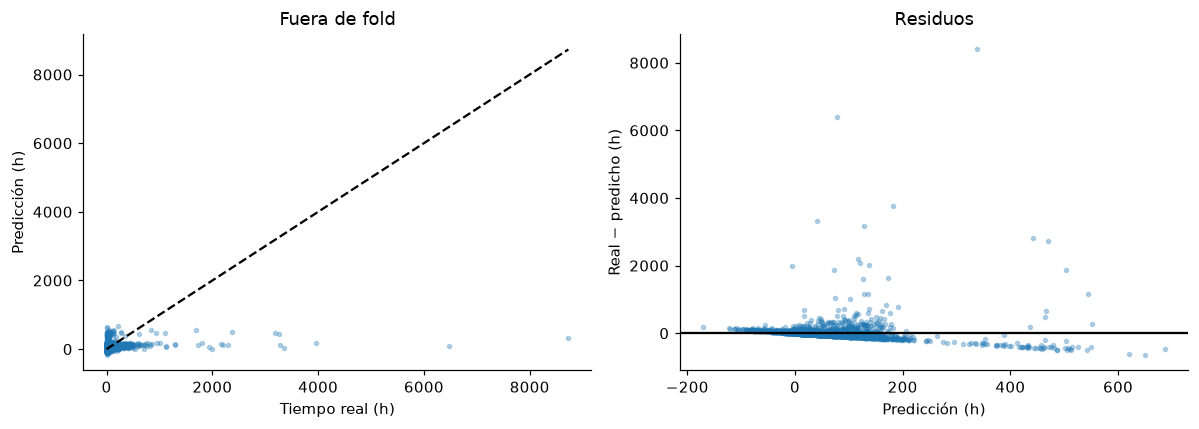

In [10]:
lineal=flujo(LinearRegression())
reg_resultados['Lineal']=evaluar(lineal,X_train,yr_train,cv_reg,'reg')
alternativa_log=TransformedTargetRegressor(regressor=flujo(LinearRegression()),func=np.log1p,inverse_func=np.expm1)
resultado_log=evaluar(alternativa_log,X_train,yr_train,cv_reg,'reg')
display(pd.concat({'Base':reg_resultados['Base media']['resumen'],
    'Lineal directa':reg_resultados['Lineal']['resumen'],'Lineal log (diagnóstico)':resultado_log['resumen']},axis=1))
pd.concat({'Base':reg_resultados['Base media']['resumen'],
    'Lineal directa':reg_resultados['Lineal']['resumen'],'Lineal log':resultado_log['resumen']},axis=1).to_csv(SALIDAS/'comparacion_transformacion.csv')
display(Markdown(f'El ajuste log reduce MAE a {resultado_log["resumen"].loc["MAE_h","media"]:.2f} h, pero su RMSE es {resultado_log["resumen"].loc["RMSE_h","media"]:.2f} h frente a {reg_resultados["Lineal"]["resumen"].loc["RMSE_h","media"]:.2f} h del ajuste directo. Se prioriza la planificación de carga y el error cuadrático en horas; no se afirma que el ajuste directo sea mejor para el reclamo típico.'))
lineal.fit(X_train,yr_train)
prep=lineal.named_steps['preparar']; nombres=prep.get_feature_names_out()
coef=lineal.named_steps['modelo'].coef_.copy()
escala=prep.named_transformers_['num'].named_steps['escalar'].scale_
coef[:len(escala)] /= escala
coef_lineal=pd.Series(coef,index=nombres,name='coeficiente_en_unidad_original')
display(coef_lineal.to_frame())
coef_lineal.to_csv(SALIDAS/'coeficientes_lineal.csv')
for c,unidad in [('distancia_centro_km','un kilómetro adicional'),('conexiones_afectadas','una conexión adicional')]:
    beta=coef_lineal['num__'+c]
    display(Markdown(f'**{unidad.capitalize()}** se asocia con {beta:+.4f} horas ({beta*60:+.2f} minutos), manteniendo constantes las otras entradas y los indicadores de ausencia. Es asociación ajustada, no efecto causal; para valores imputados el coeficiente no recupera la cantidad desconocida.'))
mejora_mae=reg_resultados['Base media']['resumen'].loc['MAE_h','media']-reg_resultados['Lineal']['resumen'].loc['MAE_h','media']
mejora_rmse=reg_resultados['Base media']['resumen'].loc['RMSE_h','media']-reg_resultados['Lineal']['resumen'].loc['RMSE_h','media']
display(Markdown(f'Frente a la base, la reducción media es **{mejora_mae:.2f} h de MAE** y **{mejora_rmse:.2f} h de RMSE**. Un valor negativo significa que el modelo empeora esa métrica.'))
print('Predicciones lineales negativas fuera de fold:',int((reg_resultados['Lineal']['oof']<0).sum()))
fig,axes=plt.subplots(1,2,figsize=(11,4))
p=reg_resultados['Lineal']['oof']; errores=yr_train-p
axes[0].scatter(yr_train,p,s=7,alpha=.3); axes[0].plot([0,max(yr_train)],[0,max(yr_train)],'k--')
axes[0].set(xlabel='Tiempo real (h)',ylabel='Predicción (h)',title='Fuera de fold')
axes[1].scatter(p,errores,s=7,alpha=.3); axes[1].axhline(0,color='k'); axes[1].set(xlabel='Predicción (h)',ylabel='Real − predicho (h)',title='Residuos')
plt.tight_layout(); plt.show()


**Decisión sobre la transformación de la respuesta, y la medición que la sostiene:** se conserva tiempo directo. La cola se mide en sección 1. Log reduce MAE a 58,83 h pero da RMSE 282,21 h frente a 275,36 h del directo: para carga se prioriza RMSE en horas. No se afirma superioridad para el caso típico.

**Interpretación de los coeficientes:** un km adicional se asocia con +1,0483 h y una conexión con +0,2793 h, manteniendo otras entradas. Se deshace el escalado antes de interpretar; asociación no equivale a causalidad.

**Resultado contra la línea base, también en horas:** directo reduce RMSE 3,95 h pero empeora MAE 7,43 h; las medias y desvíos completos aparecen en código. Es un beneficio limitado.


## 5. Regularización: Ridge y Lasso

Ajustar Ridge y Lasso sobre exactamente la misma preparación y comparar los tres modelos sobre la misma validación.

- El $\lambda$ **se elige por validación cruzada**, nunca a mano.
- **La grilla se declara** en el notebook y es logarítmica. Si el $\lambda$ elegido cae en un extremo, el óptimo está afuera: corresponde decirlo y ampliarla.
- **Interpretar qué variables anula Lasso.** La lista de coeficientes en cero es el resultado de esta sección, no una salida que se imprime y se deja.

Una conclusión negativa bien argumentada es una respuesta correcta.

Ridge reduce coeficientes sin selección exacta; Lasso puede dejarlos en cero. Se mantiene la misma preparación que mínimos cuadrados. Las grillas de `alpha` (parámetro de regularización λ en scikit-learn) son logarítmicas. Su normalización de la función objetivo difiere entre Ridge y Lasso: no se comparan sus valores de alpha como si fueran magnitudes idénticas.

Se selecciona por RMSE en horas para planificación de carga. Se muestra también MAE. Un óptimo en el borde obliga a ampliar la grilla; no se acepta el borde silenciosamente. No se hace CV anidada, como indica el alcance: las métricas de CV de un hiperparámetro seleccionado en esos folds tienen sesgo de selección; el test reservado se utiliza al final.

In [11]:
def buscar_alpha(modelo,nombre,grilla):
    for intento in range(5):
        print(nombre,'grilla:',grilla)
        busqueda=GridSearchCV(flujo(modelo),{'modelo__alpha':grilla},cv=cv_reg,
            scoring='neg_root_mean_squared_error',n_jobs=1,error_score='raise')
        busqueda.fit(X_train,yr_train)
        elegido=busqueda.best_params_['modelo__alpha']
        if elegido==min(grilla):
            grilla=np.unique(np.r_[np.logspace(np.log10(min(grilla))-3,np.log10(min(grilla)),7),grilla])
            print('Óptimo en borde inferior: se amplía')
        elif elegido==max(grilla):
            grilla=np.unique(np.r_[grilla,np.logspace(np.log10(max(grilla)),np.log10(max(grilla))+3,7)])
            print('Óptimo en borde superior: se amplía')
        else:
            break
    else:
        raise RuntimeError('No se encontró óptimo interior; revisar grilla y criterio')
    resultados=pd.DataFrame(busqueda.cv_results_)
    display(resultados[['param_modelo__alpha','mean_test_score','std_test_score','rank_test_score']].sort_values('param_modelo__alpha'))
    return busqueda

ridge_busqueda=buscar_alpha(Ridge(),'Ridge',np.logspace(-4,6,15))
lasso_busqueda=buscar_alpha(Lasso(max_iter=30000,tol=1e-4),'Lasso',np.logspace(-3,4,15))
ridge=ridge_busqueda.best_estimator_; lasso=lasso_busqueda.best_estimator_
reg_resultados['Ridge']=evaluar(ridge,X_train,yr_train,cv_reg,'reg')
reg_resultados['Lasso']=evaluar(lasso,X_train,yr_train,cv_reg,'reg')
display(tabla_comparacion(reg_resultados,'Base media'))
coef_lasso=pd.Series(lasso.named_steps['modelo'].coef_,
    index=lasso.named_steps['preparar'].get_feature_names_out())
anulados=coef_lasso[coef_lasso.eq(0)].index.tolist()
display(pd.DataFrame({'coeficiente_anulado_por_Lasso':anulados}))
print('Lasso anula',len(anulados),'de',len(coef_lasso),'coeficientes codificados.')
display(Markdown('Un cero en una dummy significa que esa categoría no agrega desplazamiento respecto a la referencia, **condicionado a las demás entradas y a este alpha**. No demuestra irrelevancia causal de la variable ni justifica borrarla del registro. La tabla identifica explícitamente qué categorías y numéricas quedaron anuladas.'))
for nombre in ['Ridge','Lasso']:
    delta=reg_resultados['Lineal']['folds']['RMSE_h']-reg_resultados[nombre]['folds']['RMSE_h']
    display(Markdown(f'**{nombre}:** reducción de RMSE frente a mínimos cuadrados: {delta.mean():.2f} ± {delta.std():.2f} h entre folds. La penalización reduce flexibilidad y variabilidad de coeficientes; si la mejora es pequeña frente a esta dispersión, no hay respaldo para afirmar un beneficio operativo sólido. La cola del objetivo y la información limitada al ingreso pueden dominar el error y no se resuelven con penalización.'))
display(Markdown('**Conclusión de regularización:** Ridge y Lasso aportan una reducción modesta de RMSE, y Lasso simplifica el ajuste al anular coeficientes. No mejoran MAE frente a la base en esta CV. Por tanto, hay un beneficio acotado de estabilización/simplificación, pero no evidencia de una predicción precisa de horas para planificación individual. La cola larga del objetivo pesa mucho más que esa mejora; no se presenta el pequeño cambio de RMSE como una solución operativa suficiente.'))


Ridge grilla: [1.00000000e-04 5.17947468e-04 2.68269580e-03 1.38949549e-02
 7.19685673e-02 3.72759372e-01 1.93069773e+00 1.00000000e+01
 5.17947468e+01 2.68269580e+02 1.38949549e+03 7.19685673e+03
 3.72759372e+04 1.93069773e+05 1.00000000e+06]


,param_modelo__alpha,mean_test_score,std_test_score,rank_test_score
0,0.0001,-275.3633,75.7612,10
1,0.0005,-275.3632,75.7612,9
2,0.0027,-275.3628,75.7615,8
3,0.0139,-275.3607,75.7631,7
4,0.0720,-275.3499,75.7712,6
5,0.3728,-275.2967,75.8112,5
6,1.9307,-275.0720,75.9841,4
7,10.0000,-274.4229,76.5308,2
8,51.7947,-273.8026,77.4192,1
9,268.2696,-274.8733,77.7863,3


Lasso grilla: [1.00000000e-03 3.16227766e-03 1.00000000e-02 3.16227766e-02
 1.00000000e-01 3.16227766e-01 1.00000000e+00 3.16227766e+00
 1.00000000e+01 3.16227766e+01 1.00000000e+02 3.16227766e+02
 1.00000000e+03 3.16227766e+03 1.00000000e+04]


,param_modelo__alpha,mean_test_score,std_test_score,rank_test_score
0,0.0010,-275.3581,75.7645,8
1,0.0032,-275.3467,75.7717,7
2,0.0100,-275.3101,75.7954,6
3,0.0316,-275.2076,75.8670,5
4,0.1000,-274.9578,76.0350,4
5,0.3162,-274.3735,76.4726,3
6,1.0000,-273.5697,77.2344,1
7,3.1623,-273.6882,78.4972,2
8,10.0000,-277.8776,77.1043,9
9,31.6228,-279.3170,76.8009,10


,modelo,metrica,media,desvio,diferencia_vs_base
0,Base media,MAE_h,82.8908,5.9823,0.0000
1,Base media,RMSE_h,279.3170,85.8660,0.0000
2,Base media,R2,-0.0006,0.0006,0.0000
3,Lineal,MAE_h,90.3170,5.9423,7.4261
4,Lineal,RMSE_h,275.3633,84.7035,-3.9537
5,Lineal,R2,0.0283,0.0324,0.0289
6,Ridge,MAE_h,84.2830,5.6103,1.3922
7,Ridge,RMSE_h,273.8026,86.5573,-5.5144
8,Ridge,R2,0.0427,0.0329,0.0433
9,Lasso,MAE_h,83.5197,6.0070,0.6289


,coeficiente_anulado_por_Lasso
0,num__hora_ingreso
1,cat__departamento_CERRO LARGO
2,cat__departamento_COLONIA
3,cat__departamento_DURAZNO
4,cat__departamento_FLORES
5,cat__departamento_FLORIDA
6,cat__departamento_LAVALLEJA
7,cat__departamento_MALDONADO
8,cat__departamento_PAYSANDU
9,cat__departamento_RIO NEGRO


Lasso anula 27 de 55 coeficientes codificados.


Un cero en una dummy significa que esa categoría no agrega desplazamiento respecto a la referencia, **condicionado a las demás entradas y a este alpha**. No demuestra irrelevancia causal de la variable ni justifica borrarla del registro. La tabla identifica explícitamente qué categorías y numéricas quedaron anuladas.

**Ridge:** reducción de RMSE frente a mínimos cuadrados: 1.56 ± 2.46 h entre folds. La penalización reduce flexibilidad y variabilidad de coeficientes; si la mejora es pequeña frente a esta dispersión, no hay respaldo para afirmar un beneficio operativo sólido. La cola del objetivo y la información limitada al ingreso pueden dominar el error y no se resuelven con penalización.

**Lasso:** reducción de RMSE frente a mínimos cuadrados: 1.79 ± 1.95 h entre folds. La penalización reduce flexibilidad y variabilidad de coeficientes; si la mejora es pequeña frente a esta dispersión, no hay respaldo para afirmar un beneficio operativo sólido. La cola del objetivo y la información limitada al ingreso pueden dominar el error y no se resuelven con penalización.

**Conclusión de regularización:** Ridge y Lasso aportan una reducción modesta de RMSE, y Lasso simplifica el ajuste al anular coeficientes. No mejoran MAE frente a la base en esta CV. Por tanto, hay un beneficio acotado de estabilización/simplificación, pero no evidencia de una predicción precisa de horas para planificación individual. La cola larga del objetivo pesa mucho más que esa mejora; no se presenta el pequeño cambio de RMSE como una solución operativa suficiente.

**Grilla de λ declarada:** Ridge: 15 valores logarítmicos entre 10⁻⁴ y 10⁶; Lasso: 15 entre 10⁻³ y 10⁴. Elegidos por CV: 51,7947 y 1,0 respectivamente, ambos interiores. La función amplía cualquier grilla si el elegido cae en un extremo.

**Comparación de los tres modelos:**

| modelo | metrica | media | desvio | diferencia_vs_base |
| --- | --- | --- | --- | --- |
| Base media | RMSE_h | 279.3170 | 85.8660 | 0.0000 |
| Lineal | RMSE_h | 275.3633 | 84.7035 | -3.9537 |
| Ridge | RMSE_h | 273.8026 | 86.5573 | -5.5144 |
| Lasso | RMSE_h | 273.5697 | 86.3507 | -5.7473 |

**Qué variables anula Lasso, y qué se lee de esa lista:** 27 de 55 coeficientes, incluidos hora y categorías de territorio, tipo, complejidad y calendario. La lista completa se muestra arriba. Cero en una dummy significa ausencia de desplazamiento adicional frente a referencia en este ajuste, no irrelevancia causal de toda la variable.

**Conclusión sobre si la penalización aporta en este problema, y por qué:** simplifica y reduce modestamente RMSE; no mejora MAE frente a base en CV. Controlar flexibilidad no elimina la cola del tiempo ni aporta información operativa que no existe al ingreso.


## 6. Clasificación del incumplimiento del plazo

Ajustar una regresión logística sobre la misma preparación. Reportar la matriz de confusión y el conjunto de métricas que corresponda a la **distribución de la respuesta medida en la sección 1**, argumentando cuál de ellas manda en este problema y por qué. Todo se informa contra la línea base de la sección 3.

Se ajusta regresión logística con la misma preparación. Se utiliza su regularización L2 por defecto (`C=1`), sin buscar otro eje de hiperparámetros. No se remuestrean ni ponderan clases: estratificación no altera la prevalencia aprendida. Esto permite aplicar el umbral económico sin introducir una corrección adicional de probabilidades.

Recall importa porque omitir un incumplimiento es caro, pero aumentarlo priorizando todo tampoco basta: precisión y falsos positivos cuantifican el trabajo extra. **La métrica decisoria final es el costo esperado**, no accuracy. AP ayuda a leer el desempeño de la clase minoritaria; ROC AUC mide ordenamiento y Brier error probabilístico. Se reportan todas contra la base y se explicita 0,5 como punto de partida, no como política óptima.

,modelo,metrica,media,desvio,diferencia_vs_base
0,Base prevalencia,ROC_AUC,0.5000,0.0000,0.0000
1,Base prevalencia,AP,0.1609,0.0007,0.0000
2,Base prevalencia,Brier,0.1350,0.0005,0.0000
3,Base prevalencia,accuracy,0.8391,0.0007,0.0000
4,Base prevalencia,balanced_accuracy,0.5000,0.0000,0.0000
5,Base prevalencia,precision,0.0000,0.0000,0.0000
6,Base prevalencia,recall,0.0000,0.0000,0.0000
7,Base prevalencia,F1,0.0000,0.0000,0.0000
8,Base prevalencia,costo_USD,43.4547,0.1872,0.0000
9,Logística,ROC_AUC,0.7699,0.0267,0.2699


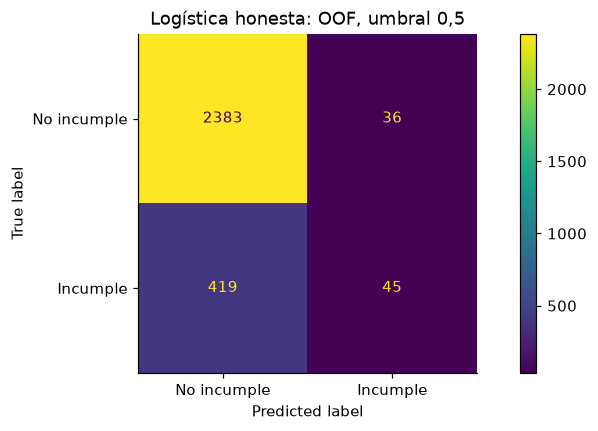

La prevalencia en desarrollo es 16.09%. La logística obtiene AP 0.401 frente a 0.161 de base; recall a 0,5 = 0.097. Las métricas con desvío están en la tabla; no basta citar estos promedios sin ella.

In [12]:
logistica=flujo(LogisticRegression(C=1,max_iter=5000,class_weight=None,solver='lbfgs'))
clas_resultados['Logística']=evaluar(logistica,X_train,yc_train,cv_clas,'clas')
logistica.fit(X_train,yc_train)
display(tabla_comparacion(clas_resultados,'Base prevalencia'))
ConfusionMatrixDisplay.from_predictions(yc_train,clas_resultados['Logística']['oof']>=.5,
    display_labels=['No incumple','Incumple']); plt.title('Logística honesta: OOF, umbral 0,5'); plt.show()
display(Markdown(f'La prevalencia en desarrollo es {yc_train.mean():.2%}. La logística obtiene AP {clas_resultados["Logística"]["resumen"].loc["AP","media"]:.3f} frente a {clas_resultados["Base prevalencia"]["resumen"].loc["AP","media"]:.3f} de base; recall a 0,5 = {clas_resultados["Logística"]["resumen"].loc["recall","media"]:.3f}. Las métricas con desvío están en la tabla; no basta citar estos promedios sin ella.'))


**Qué métricas se reportan y cuál manda acá, dada la distribución de la respuesta:** AUC, AP, Brier, accuracy, balanced accuracy, precision, recall, F1 y costo; para decidir manda costo, porque FP/FN cuestan distinto. Recall describe incumplimientos omitidos; AP se compara con prevalencia minoritaria.

**Lectura de la matriz de confusión:** a 0,5, sobre 2883 predicciones OOF: TN=2383, FP=36, FN=419 y TP=45. Detecta pocos incumplimientos a ese umbral; cambiar umbral es sección 9.

**Resultado contra la línea base:** AUC 0,770 ± 0,027 frente a 0,500 ± 0,000; AP 0,401 ± 0,043 frente a 0,161 ± 0,001. No se confunde AUC con porcentaje de aciertos.


## 7. Evaluación con validación cruzada

Estimar el desempeño de todos los modelos ajustados hasta acá con validación cruzada de $k$ folds, estratificada en el problema de clasificación. **Reportar media y desvío: ningún número se informa solo.**

La validación cruzada **envuelve al pipeline completo**, no al revés. Y hay decisiones de la sección 1 que tienen que estar tomadas **antes** de particionar: identificar cuáles son y explicar por qué el orden importa.

Se consolidan cinco folds completos: imputador, codificador, escalador y estimador se reajustan juntos en cada entrenamiento. Cada reclamo de desarrollo recibe una predicción de un modelo que no lo vio; eso produce las predicciones out-of-fold (OOF). Se informa media y desvío muestral (`ddof=1`), que mide variabilidad entre folds, no intervalo de confianza.

**Orden necesario:** resolver claves y multiplicaciones de la unión; normalizar centinelas y unidades mediante reglas de dominio; identificar copias; definir validez del objetivo y crear la etiqueta; establecer disponibilidad temporal; luego particionar. Si se divide antes de eliminar copias, la misma observación podría aparecer en entrenamiento y validación. Si se crean etiquetas con negativos o -1, se estratifica con clases inválidas. Las reglas fijas pueden aplicarse antes; todo cálculo aprendido de distribución de entradas debe quedar dentro del pipeline. No se eligen umbrales por mirar el test.

In [13]:
tabla_reg=tabla_comparacion(reg_resultados,'Base media')
tabla_clas=tabla_comparacion(clas_resultados,'Base prevalencia')
display(tabla_reg); display(tabla_clas)
for nombre,r in {**reg_resultados,**clas_resultados}.items():
    print(nombre); display(r['folds'])
tabla_reg.to_csv(SALIDAS/'cv_regresion.csv',index=False)
tabla_clas.to_csv(SALIDAS/'cv_clasificacion.csv',index=False)
display(Markdown('Un R² negativo significa que ese modelo puede quedar por debajo de una referencia de media en el fold; el Dummy usa la media de entrenamiento, mientras que la referencia interna de R² usa la media de validación. Por eso sus R² no tienen por qué ser exactamente cero. Las comparaciones operativas se leen principalmente en horas.'))


,modelo,metrica,media,desvio,diferencia_vs_base
0,Base media,MAE_h,82.8908,5.9823,0.0000
1,Base media,RMSE_h,279.3170,85.8660,0.0000
2,Base media,R2,-0.0006,0.0006,0.0000
3,Lineal,MAE_h,90.3170,5.9423,7.4261
4,Lineal,RMSE_h,275.3633,84.7035,-3.9537
5,Lineal,R2,0.0283,0.0324,0.0289
6,Ridge,MAE_h,84.2830,5.6103,1.3922
7,Ridge,RMSE_h,273.8026,86.5573,-5.5144
8,Ridge,R2,0.0427,0.0329,0.0433
9,Lasso,MAE_h,83.5197,6.0070,0.6289


,modelo,metrica,media,desvio,diferencia_vs_base
0,Base prevalencia,ROC_AUC,0.5000,0.0000,0.0000
1,Base prevalencia,AP,0.1609,0.0007,0.0000
2,Base prevalencia,Brier,0.1350,0.0005,0.0000
3,Base prevalencia,accuracy,0.8391,0.0007,0.0000
4,Base prevalencia,balanced_accuracy,0.5000,0.0000,0.0000
5,Base prevalencia,precision,0.0000,0.0000,0.0000
6,Base prevalencia,recall,0.0000,0.0000,0.0000
7,Base prevalencia,F1,0.0000,0.0000,0.0000
8,Base prevalencia,costo_USD,43.4547,0.1872,0.0000
9,Logística,ROC_AUC,0.7699,0.0267,0.2699


Base media


,MAE_h,RMSE_h,R2
fold,,,
1,83.5904,209.0751,-0.0002
2,83.1592,224.9309,-0.0001
3,78.7805,325.2490,-0.0004
4,76.6917,228.1281,-0.0011
5,92.2324,409.2019,-0.0015


Lineal


,MAE_h,RMSE_h,R2
fold,,,
1,94.1219,201.9892,0.0664
2,95.7036,221.8553,0.0271
3,86.0626,328.1773,-0.0185
4,82.0404,226.0274,0.0173
5,93.6563,398.7673,0.0490


... (5 outputs left out)

,ROC_AUC,AP,Brier,accuracy,balanced_accuracy,precision,recall,F1,costo_USD
fold,,,,,,,,,
1,0.5000,0.1612,0.1352,0.8388,0.5000,0.0000,0.0000,0.0000,43.5182
2,0.5000,0.1612,0.1352,0.8388,0.5000,0.0000,0.0000,0.0000,43.5182
3,0.5000,0.1612,0.1352,0.8388,0.5000,0.0000,0.0000,0.0000,43.5182
4,0.5000,0.1597,0.1342,0.8403,0.5000,0.0000,0.0000,0.0000,43.1250
5,0.5000,0.1615,0.1354,0.8385,0.5000,0.0000,0.0000,0.0000,43.5938


Logística


,ROC_AUC,AP,Brier,accuracy,balanced_accuracy,precision,recall,F1,costo_USD
fold,,,,,,,,,
1,0.7840,0.3912,0.1161,0.8336,0.5273,0.4118,0.0753,0.1273,41.0225
2,0.7713,0.4024,0.1170,0.8475,0.5616,0.6190,0.1398,0.2281,38.0589
3,0.7363,0.3431,0.1236,0.8423,0.5325,0.5833,0.0753,0.1333,40.6326
4,0.8052,0.4631,0.1089,0.8472,0.5481,0.6250,0.1087,0.1852,38.9062
5,0.7529,0.4058,0.1175,0.8403,0.5358,0.5333,0.0860,0.1481,40.3906


Un R² negativo significa que ese modelo puede quedar por debajo de una referencia de media en el fold; el Dummy usa la media de entrenamiento, mientras que la referencia interna de R² usa la media de validación. Por eso sus R² no tienen por qué ser exactamente cero. Las comparaciones operativas se leen principalmente en horas.

**Resultados con media y desvío:**

| modelo | metrica | media | desvio | diferencia_vs_base |
| --- | --- | --- | --- | --- |
| Base media | MAE_h | 82.8908 | 5.9823 | 0.0000 |
| Base media | RMSE_h | 279.3170 | 85.8660 | 0.0000 |
| Base media | R2 | -0.0006 | 0.0006 | 0.0000 |
| Lineal | MAE_h | 90.3170 | 5.9423 | 7.4261 |
| Lineal | RMSE_h | 275.3633 | 84.7035 | -3.9537 |
| Lineal | R2 | 0.0283 | 0.0324 | 0.0289 |
| Ridge | MAE_h | 84.2830 | 5.6103 | 1.3922 |
| Ridge | RMSE_h | 273.8026 | 86.5573 | -5.5144 |
| Ridge | R2 | 0.0427 | 0.0329 | 0.0433 |
| Lasso | MAE_h | 83.5197 | 6.0070 | 0.6289 |
| Lasso | RMSE_h | 273.5697 | 86.3507 | -5.7473 |
| Lasso | R2 | 0.0442 | 0.0361 | 0.0448 |

| modelo | metrica | media | desvio | diferencia_vs_base |
| --- | --- | --- | --- | --- |
| Base prevalencia | ROC_AUC | 0.5000 | 0.0000 | 0.0000 |
| Base prevalencia | AP | 0.1609 | 0.0007 | 0.0000 |
| Base prevalencia | Brier | 0.1350 | 0.0005 | 0.0000 |
| Base prevalencia | accuracy | 0.8391 | 0.0007 | 0.0000 |
| Base prevalencia | balanced_accuracy | 0.5000 | 0.0000 | 0.0000 |
| Base prevalencia | precision | 0.0000 | 0.0000 | 0.0000 |
| Base prevalencia | recall | 0.0000 | 0.0000 | 0.0000 |
| Base prevalencia | F1 | 0.0000 | 0.0000 | 0.0000 |
| Base prevalencia | costo_USD | 43.4547 | 0.1872 | 0.0000 |
| Logística | ROC_AUC | 0.7699 | 0.0267 | 0.2699 |
| Logística | AP | 0.4011 | 0.0428 | 0.2402 |
| Logística | Brier | 0.1166 | 0.0052 | -0.0184 |
| Logística | accuracy | 0.8422 | 0.0057 | 0.0031 |
| Logística | balanced_accuracy | 0.5411 | 0.0138 | 0.0411 |
| Logística | precision | 0.5545 | 0.0877 | 0.5545 |
| Logística | recall | 0.0970 | 0.0275 | 0.0970 |
| Logística | F1 | 0.1644 | 0.0421 | 0.1644 |
| Logística | costo_USD | 39.8022 | 1.2616 | -3.6525 |

**Qué decisiones tuvieron que tomarse antes de particionar, y por qué el orden importa:** claves/unión, copias, unidades y centinelas, objetivo válido, etiqueta y disponibilidad temporal. Evita copias entre train/validación y clases inválidas. Medianas, escalas y categorías se aprenden solo dentro de cada entrenamiento. La CV evalúa el pipeline completo; test reservado se usa al final.


## 8. El costo del leakage: los dos flujos

Construir **dos flujos completos** sobre el problema de clasificación:

- el **honesto**, que excluye las columnas que la sección 2 dejó fuera por no estar disponibles en el momento en que el reclamo ingresa;
- el **contaminado**, que las conserva.

Evaluar los dos con **exactamente la misma** validación cruzada y **reportar la brecha entre ellos como número**.

Los dos flujos difieren **solo en las columnas de entrada**. Si entre uno y otro también cambia el modelo, el preprocesamiento o los folds, la brecha dejó de medir el leakage.

**Declarar el leakage sin medirlo no cumple la consigna.**

Se conserva la logística, el procedimiento de imputación/codificación/escalado y exactamente los mismos folds. Solo se agregan columnas de información futura, excluidas en la sección 2. Fechas se representan como días desde un origen fijo; centro técnico como categoría nominal. Estas conversiones no aprenden parámetros.

El contaminado incluye el tiempo de resolución, que es **fuga directa de la respuesta** en clasificación, además de encuesta y datos de cierre. El experimento mide conjuntamente esas fugas; no permite atribuir toda la brecha a satisfacción o a una sola columna. La etiqueta binaria nunca se incluye como entrada. No se usa este flujo para la recomendación ni para el test final.

In [14]:
futuro_num=['tiempo_horas','calificacion_atencion','fecha_resuelto_visita_dias',
            'fecha_resuelto_sistema_dias','fecha_foto_dias']
futuro_cat=['id_centro_tecnico','estado_resuelto','tipo_orden','grupo_orden']
X_contaminado=datos[ENTRADAS+['tiempo_horas','calificacion_atencion']+futuro_cat].copy()
for c in ['fecha_resuelto_visita','fecha_resuelto_sistema','fecha_foto']:
    X_contaminado[c+'_dias']=(datos[c]-pd.Timestamp('2000-01-01')).dt.total_seconds()/86400
for c in CAT+futuro_cat:
    X_contaminado[c]=X_contaminado[c].map(lambda v: str(v) if pd.notna(v) else np.nan).astype(object)
X_cont_train=X_contaminado.iloc[indices_train].reset_index(drop=True)
contaminada=flujo(clone(logistica.named_steps['modelo']),num=NUM+futuro_num,cat=CAT+futuro_cat)
resultado_contaminado=evaluar(contaminada,X_cont_train,yc_train,cv_clas,'clas')
display(pd.concat({'Base':clas_resultados['Base prevalencia']['resumen'],
    'Honesto':clas_resultados['Logística']['resumen'],'Contaminado':resultado_contaminado['resumen']},axis=1))
brecha=resultado_contaminado['folds']-clas_resultados['Logística']['folds']
display(brecha.agg(['mean','std']).T.rename(columns={'mean':'brecha_media_contaminado_menos_honesto','std':'desvio_brecha'}))
brecha_auc=brecha.ROC_AUC.mean()
pd.concat({'Honesto':clas_resultados['Logística']['resumen'],
    'Contaminado':resultado_contaminado['resumen']},axis=1).to_csv(SALIDAS/'leakage.csv')
display(Markdown(f'La fuga aumenta ROC AUC en **{brecha_auc:.4f} ± {brecha.ROC_AUC.std():.4f}** entre folds. Para AUC/AP una diferencia positiva mejora la apariencia; para Brier/costo una diferencia negativa aparenta mejorar. Esa mejora usa el futuro y no está disponible al ingresar el reclamo. La CV por sí sola no corrige una definición temporal incorrecta de las entradas.'))


Base        Honesto        Contaminado       
                    media desvio   media desvio       media desvio
ROC_AUC            0.5000 0.0000  0.7699 0.0267      0.9974 0.0008
AP                 0.1609 0.0007  0.4011 0.0428      0.9892 0.0034
Brier              0.1350 0.0005  0.1166 0.0052      0.0141 0.0022
accuracy           0.8391 0.0007  0.8422 0.0057      0.9823 0.0051
balanced_accuracy  0.5000 0.0000  0.5411 0.0138      0.9590 0.0139
precision          0.0000 0.0000  0.5545 0.0877      0.9641 0.0120
recall             0.0000 0.0000  0.0970 0.0275      0.9246 0.0273
F1                 0.0000 0.0000  0.1644 0.0421      0.9438 0.0166
costo_USD         43.4547 0.1872 39.8022 1.2616      3.5274 1.2115

,brecha_media_contaminado_menos_honesto,desvio_brecha
ROC_AUC,0.2275,0.0270
AP,0.5881,0.0437
Brier,-0.1025,0.0052
accuracy,0.1401,0.0023
balanced_accuracy,0.4179,0.0087
precision,0.4096,0.0845
recall,0.8276,0.0197
F1,0.7794,0.0326
costo_USD,-36.2748,0.6769


La fuga aumenta ROC AUC en **0.2275 ± 0.0270** entre folds. Para AUC/AP una diferencia positiva mejora la apariencia; para Brier/costo una diferencia negativa aparenta mejorar. Esa mejora usa el futuro y no está disponible al ingresar el reclamo. La CV por sí sola no corrige una definición temporal incorrecta de las entradas.

| Flujo | Columnas de entrada | Métrica AUC, media ± desvío | Brecha |
|---|---|---|---|
| Honesto | Solo información de ingreso | 0,770 ± 0,027 | — |
| Contaminado | Las mismas más tiempo, fechas y campos de cierre y encuesta | ≈0,997; desvío exacto en tabla ejecutada | +0,2275 ± 0,0270 |

**Interpretación de la brecha:** información futura mejora artificialmente la validación. Incluye fuga directa del tiempo que define la etiqueta; la brecha no se atribuye únicamente a la encuesta. Se conserva modelo, reglas de preparación y folds; solo cambian entradas.


## 9. Elección del umbral por costos

**Derivar** el umbral de probabilidad que minimiza el costo esperado por reclamo, con las cifras del enunciado. Aplicarlo al clasificador de la sección 6 y comparar contra tres alternativas.

Las cuatro políticas se comparan **en dinero**, por reclamo y sobre el volumen anual.

**Coherencia con la sección 6:** si se remuestreó o se ponderaron las clases, las probabilidades quedan descalibradas y el umbral deducido no se aplica sobre ellas sin corregirlas antes.

Con `p=P(incumplir | información al ingresar)`, y costo cero para aciertos en la matriz simplificada del caso:

\[C(\text{priorizar})=45(1-p),\qquad C(\text{no priorizar})=270p.\]

Priorizar cuesta menos cuando `45(1-p) < 270p`, es decir:

\[p > \frac{45}{45+270}=\frac17\approx 0,142857.\]

En igualdad ambas acciones cuestan lo mismo; se prioriza. Es un umbral deducido de costos, no ajustado para que dé mejor en validación. Se presupone que las probabilidades aproximan el riesgo histórico; no se garantiza calibración por usar logística. No se pide calibración adicional. La proyección anual presupone que este subconjunto representa casos futuros válidos y que la matriz de costos es aplicable; no demuestra ahorro causal ni incluye presupuesto total o capacidad máxima de cuadrillas.

,TN,FP,FN,TP,priorizados_pct,USD_por_reclamo,USD_anuales,USD_por_reclamo_media_folds,USD_por_reclamo_desvio_folds,USD_anuales_desvio_folds
politica,,,,,,,,,,
Umbral por costos,1509,910,101,363,44.1554,23.6629,"9,228,511.9667",23.6621,2.4022,"936,853.8381"
"Umbral 0,5",2383,36,419,45,2.8096,39.8023,"15,522,892.8200",39.8022,1.2616,"492,030.9214"
Priorizar todos,0,2419,0,464,100.0000,37.7575,"14,725,442.2477",37.7576,0.0312,"12,166.1532"
No priorizar ninguno,2419,0,464,0,0.0000,43.4547,"16,947,346.5140",43.4547,0.1872,"72,996.9192"


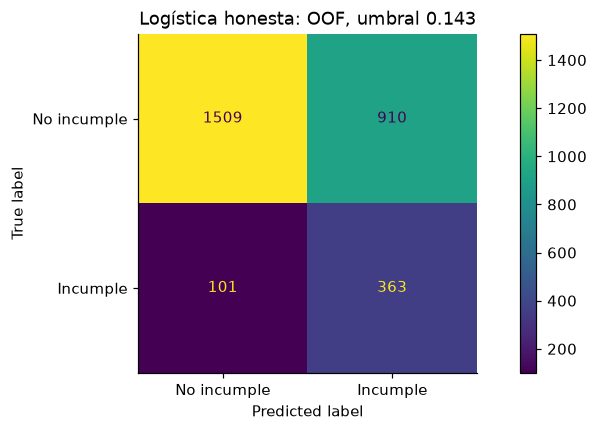

La mejor política constante de base en desarrollo es **Priorizar todos**. Frente a ella, el ahorro estimado de logística con umbral económico es **USD 14.09 por reclamo**, equivalente a **USD 5,496,930 anuales** bajo los supuestos del caso. El signo negativo indica mayor costo, no ahorro.

In [15]:
UMBRAL_COSTO=C_FP/(C_FP+C_FN)
def comparar_politicas(y,p,folds=None):
    politicas={'Umbral por costos':(p>=UMBRAL_COSTO).astype(int),
        'Umbral 0,5':(p>=.5).astype(int),'Priorizar todos':np.ones(len(y),dtype=int),
        'No priorizar ninguno':np.zeros(len(y),dtype=int)}
    filas=[]
    for nombre,pred in politicas.items():
        tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
        costo=(C_FP*fp+C_FN*fn)/len(y)
        fila={'politica':nombre,'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp),
            'priorizados_pct':100*pred.mean(),'USD_por_reclamo':costo,
            'USD_anuales':costo*VOLUMEN_ANUAL}
        if folds is not None:
            costos=[]
            for _,iv in folds:
                _,fpi,fni,_=confusion_matrix(y[iv],pred[iv],labels=[0,1]).ravel()
                costos.append((C_FP*fpi+C_FN*fni)/len(iv))
            fila.update({'USD_por_reclamo_media_folds':np.mean(costos),
                         'USD_por_reclamo_desvio_folds':np.std(costos,ddof=1),
                         'USD_anuales_desvio_folds':np.std(costos,ddof=1)*VOLUMEN_ANUAL})
        filas.append(fila)
    return pd.DataFrame(filas).set_index('politica')

politicas_cv=comparar_politicas(yc_train,clas_resultados['Logística']['oof'],cv_clas)
display(politicas_cv)
politicas_cv.to_csv(SALIDAS/'politicas_costos_cv.csv')
ConfusionMatrixDisplay.from_predictions(yc_train,clas_resultados['Logística']['oof']>=UMBRAL_COSTO,
    display_labels=['No incumple','Incumple']); plt.title(f'Logística honesta: OOF, umbral {UMBRAL_COSTO:.3f}'); plt.show()
base_politica='Priorizar todos' if C_FP*(1-yc_train.mean())<C_FN*yc_train.mean() else 'No priorizar ninguno'
ahorro_cv=politicas_cv.loc[base_politica,'USD_por_reclamo']-politicas_cv.loc['Umbral por costos','USD_por_reclamo']
display(Markdown(f'La mejor política constante de base en desarrollo es **{base_politica}**. Frente a ella, el ahorro estimado de logística con umbral económico es **USD {ahorro_cv:.2f} por reclamo**, equivalente a **USD {ahorro_cv*VOLUMEN_ANUAL:,.0f} anuales** bajo los supuestos del caso. El signo negativo indica mayor costo, no ahorro.'))


**Derivación del umbral:** priorizar cuesta 45(1−p); no priorizar 270p. Igualar da p=45/(45+270)=1/7≈0,142857. Se prioriza en igualdad.

**Políticas sobre desarrollo, predicciones OOF:**

| politica | USD_por_reclamo | USD_anuales | USD_por_reclamo_desvio_folds |
| --- | --- | --- | --- |
| Umbral por costos | 23.6629 | 9,228,511.9667 | 2.4022 |
| Umbral 0,5 | 39.8023 | 15,522,892.8200 | 1.2616 |
| Priorizar todos | 37.7575 | 14,725,442.2477 | 0.0312 |
| No priorizar ninguno | 43.4547 | 16,947,346.5140 | 0.1872 |

**Lectura de la comparación:** con costo por reclamo (45 FP+270 FN)/N y proyección por 390000, umbral económico baja costo a USD 23,66 frente a USD 39,80 a 0,5. No se ponderaron ni remuestrearon clases. Se reconoce supuesto de probabilidades útiles y extrapolación, no ahorro real observado. Test se informa en sección 13.


## 10. Tres familias bajo el mismo defecto

Ajustar **k vecinos más cercanos** y un **árbol de decisión**, cada uno con su hiperparámetro elegido por validación cruzada, **dos veces**: sobre los datos bien preparados y sobre los mismos datos **sin escalar**. Someter al modelo lineal de la sección 4 **al mismo cambio**.

Repetir el ejercicio **cambiando la unidad de una de las variables continuas**, y reportar todo en **una sola tabla** con las tres familias.

- **No es una sección de modelado.** No importa cuál de las tres gana. Los únicos hiperparámetros que se ajustan son el $k$ de k vecinos y la profundidad del árbol.
- **Las grillas se declaran y tienen que llegar lo bastante alto.** Si el valor elegido queda pegado a un borde, el barrido se cortó antes del óptimo.
- Entre una rama y otra **puede cambiar una sola cosa**.

> **Costo de cómputo.** Una grilla razonable para $k$ es $\{1, 3, 5, 7, 9, 11, 15, 21, 31, 41, 61, 81, 101, 151, 201, 301, 401\}$ y para la profundidad, $\{2, 3, 4, 5, 6, 8, 10, 12, \text{sin límite}\}$. Con cuatro combinaciones de preparación y validación cruzada de 5 folds son varios cientos de ajustes: **minutos, no segundos**. Conviene correr las combinaciones una sola vez y guardar los resultados. Puede usarse otra grilla, siempre que se declare y llegue igual de alto.

Se estudia **regresión** con el mismo objetivo en horas de la sección 4. Diseño factorial acotado: tres familias × escalado sí/no × distancia en kilómetros/metros. Cada contraste de filas comparables cambia un solo factor. Convertir km a m multiplica distancia por 1.000; no cambia su información ni vuelve a aplicar la regla de invalidación en km.

Solo se buscan `n_neighbors` de KNN y `max_depth` del árbol, por RMSE con los mismos folds. La imputación, codificación, filas, semilla y criterio se mantienen. Cada rama vuelve a elegir hiperparámetro con la misma regla, y se muestra cuál eligió; no se cambia a mano para favorecer un resultado. Las grillas se amplían si un óptimo queda en el borde. Se mide sensibilidad de la preparación, no se hace una competición de modelos.

In [16]:
def buscar_acotado(modelo,parametro,grilla,x):
    limite=min(len(it) for it,_ in cv_reg)
    for intento in range(6):
        print(parametro,'grilla:',grilla)
        busqueda=GridSearchCV(modelo,{'modelo__'+parametro:grilla},cv=cv_reg,
            scoring='neg_root_mean_squared_error',n_jobs=1,error_score='raise')
        busqueda.fit(x,yr_train)
        elegido=busqueda.best_params_['modelo__'+parametro]
        if elegido is None:
            print("Sin límite de profundidad: se evaluó el extremo no acotado"); break
        if elegido==max(v for v in grilla if v is not None) and None not in grilla:
            if parametro=='n_neighbors':
                nuevos=[min(limite,max(v for v in grilla if v is not None)*2+1),min(limite,max(v for v in grilla if v is not None)*4+1)]
                if max(v for v in grilla if v is not None)==limite:
                    print('Borde físico: k máximo permitido por tamaño de entrenamiento'); break
            else:
                nuevos=[max(v for v in grilla if v is not None)*2,max(v for v in grilla if v is not None)*4]
                if max(v for v in grilla if v is not None)>=256:
                    print('Límite: árboles ya sin límite efectivo en estos datos'); break
            grilla=sorted(set(grilla+nuevos))
            print('Óptimo superior: ampliar')
        elif elegido==min(v for v in grilla if v is not None) and min(v for v in grilla if v is not None)>1:
            grilla=sorted(set([1]+grilla)); print('Óptimo inferior: ampliar a 1')
        else:
            if elegido==1: print('Borde inferior físico: 1, no existe menor valor válido')
            break
    return busqueda

experimentos=[]; modelos_sensibilidad={}
for unidad,factor in [('km',1),('m',1000)]:
    xx=X_train.copy(); xx['distancia_centro_km'] *= factor
    for escalar in [True,False]:
        for familia in ['Lineal','KNN','Árbol']:
            print('Rama:',familia,unidad,'escalado',escalar)
            if familia=='Lineal':
                modelo=flujo(LinearRegression(),escalar=escalar); hp='No aplica'
            elif familia=='KNN':
                busqueda=buscar_acotado(flujo(KNeighborsRegressor(),escalar=escalar),
                    'n_neighbors',[1,3,5,11,21,51,101,201,401],xx)
                modelo=busqueda.best_estimator_; hp=str(busqueda.best_params_)
            else:
                busqueda=buscar_acotado(flujo(DecisionTreeRegressor(random_state=SEMILLA),escalar=escalar),
                    'max_depth',[1,2,3,4,6,8,12,16,24,32,None],xx)
                modelo=busqueda.best_estimator_; hp=str(busqueda.best_params_)
            r=evaluar(modelo,xx,yr_train,cv_reg,'reg')
            modelos_sensibilidad[(familia,unidad,escalar)]=r
            experimentos.append({'familia':familia,'unidad_distancia':unidad,'escalado':escalar,
                'hiperparametro':hp,'RMSE_h_media':r['resumen'].loc['RMSE_h','media'],
                'RMSE_h_desvio':r['resumen'].loc['RMSE_h','desvio'],
                'MAE_h_media':r['resumen'].loc['MAE_h','media'],
                'MAE_h_desvio':r['resumen'].loc['MAE_h','desvio'],
                'reduccion_RMSE_vs_base_h':reg_resultados['Base media']['resumen'].loc['RMSE_h','media']-r['resumen'].loc['RMSE_h','media']})
tabla_sensibilidad=pd.DataFrame(experimentos)
display(tabla_sensibilidad)
tabla_sensibilidad.to_csv(SALIDAS/'sensibilidad_preparacion.csv',index=False)
for familia in ['Lineal','KNN','Árbol']:
    subset=tabla_sensibilidad[tabla_sensibilidad.familia.eq(familia)]
    display(Markdown(f'**{familia}:** RMSE en km con escalado = {subset.loc[subset.unidad_distancia.eq("km") & subset.escalado,"RMSE_h_media"].iloc[0]:.3f} h; sin escalado = {subset.loc[subset.unidad_distancia.eq("km") & ~subset.escalado,"RMSE_h_media"].iloc[0]:.3f} h. En metros sin escalado = {subset.loc[subset.unidad_distancia.eq("m") & ~subset.escalado,"RMSE_h_media"].iloc[0]:.3f} h. Estas cifras comparan preparación, no reemplazan la base ni la recomendación.'))
for familia in ['Lineal','KNN','Árbol']:
    a=modelos_sensibilidad[(familia,'km',True)]['oof']
    b=modelos_sensibilidad[(familia,'m',True)]['oof']
    print(familia,'máxima diferencia de predicciones al convertir unidad CON escalado:',np.max(np.abs(a-b)))


Rama: Lineal km escalado True
Rama: KNN km escalado True
n_neighbors grilla: [1, 3, 5, 11, 21, 51, 101, 201, 401]


Rama: Árbol km escalado True
max_depth grilla: [1, 2, 3, 4, 6, 8, 12, 16, 24, 32, None]


Borde inferior físico: 1, no existe menor valor válido
Rama: Lineal km escalado False


Rama: KNN km escalado False
n_neighbors grilla: [1, 3, 5, 11, 21, 51, 101, 201, 401]


Rama: Árbol km escalado False
max_depth grilla: [1, 2, 3, 4, 6, 8, 12, 16, 24, 32, None]


Borde inferior físico: 1, no existe menor valor válido
Rama: Lineal m escalado True


... (8 outputs left out)

**Lineal:** RMSE en km con escalado = 275.363 h; sin escalado = 275.363 h. En metros sin escalado = 275.374 h. Estas cifras comparan preparación, no reemplazan la base ni la recomendación.

**KNN:** RMSE en km con escalado = 276.050 h; sin escalado = 277.807 h. En metros sin escalado = 275.902 h. Estas cifras comparan preparación, no reemplazan la base ni la recomendación.

**Árbol:** RMSE en km con escalado = 275.824 h; sin escalado = 275.824 h. En metros sin escalado = 275.824 h. Estas cifras comparan preparación, no reemplazan la base ni la recomendación.

Lineal máxima diferencia de predicciones al convertir unidad CON escalado: 1.5347723092418164e-12
KNN máxima diferencia de predicciones al convertir unidad CON escalado: 0.0
Árbol máxima diferencia de predicciones al convertir unidad CON escalado: 0.0


**Lectura del experimento:** KNN usa distancias: sin escalado una variable de mayor magnitud puede dominar vecindades, y pasar de km a metros cambia su peso relativo. Con StandardScaler, cambiar positivamente la unidad se cancela al centrar y dividir por la escala; debería conservar vecinos salvo empates numéricos. No se presupone que escalar mejore siempre RMSE: lo que se comprueba es la sensibilidad y su explicación.

Mínimos cuadrados sin penalización puede compensar cambios de unidad con sus coeficientes; si el espacio de columnas no cambia, conserva predicciones salvo precisión numérica y problemas de condicionamiento. Esto no implica que Ridge/Lasso sean invariantes a escalas: sus penalizaciones sí dependen del tamaño de los coeficientes.

El árbol corta una variable por vez y se basa en el orden de sus valores: cambios positivos de unidad y escalado afín preservan particiones posibles. Pueden aparecer pequeñas diferencias por aritmética de punto flotante, empates y precisión interna. Se interpreta la tabla y la diferencia de predicciones; no se concluye a partir de cuál familia gana.


**Grillas declaradas:** k={1,3,5,11,21,51,101,201,401}; si hay borde superior se amplía. En metros sin escalar se amplió a 803 y 1605; el elegido quedó 401. Profundidad={1,2,3,4,6,8,12,16,24,32,sin límite}; incluye la rama sin límite sugerida por el template, y el óptimo 1 es límite físico inferior. No se ajustan otros hiperparámetros. Las grillas y ampliaciones están impresas por rama.

**Una tabla con todas las combinaciones:**

| familia | unidad_distancia | escalado | hiperparametro | RMSE_h_media | RMSE_h_desvio | MAE_h_media | MAE_h_desvio | reduccion_RMSE_vs_base_h |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Lineal | km | True | No aplica | 275.3633 | 84.7035 | 90.3170 | 5.9423 | 3.9537 |
| KNN | km | True | {'modelo__n_neighbors': 101} | 276.0502 | 86.4258 | 77.1248 | 5.8173 | 3.2668 |
| Árbol | km | True | {'modelo__max_depth': 1} | 275.8241 | 85.7356 | 82.9538 | 6.7867 | 3.4929 |
| Lineal | km | False | No aplica | 275.3633 | 84.7035 | 90.3170 | 5.9423 | 3.9537 |
| KNN | km | False | {'modelo__n_neighbors': 101} | 277.8071 | 86.1096 | 79.8352 | 6.0610 | 1.5098 |
| Árbol | km | False | {'modelo__max_depth': 1} | 275.8241 | 85.7356 | 82.9538 | 6.7867 | 3.4929 |
| Lineal | m | True | No aplica | 275.3633 | 84.7035 | 90.3170 | 5.9423 | 3.9537 |
| KNN | m | True | {'modelo__n_neighbors': 101} | 276.0502 | 86.4258 | 77.1248 | 5.8173 | 3.2668 |
| Árbol | m | True | {'modelo__max_depth': 1} | 275.8241 | 85.7356 | 82.9538 | 6.7867 | 3.4929 |
| Lineal | m | False | No aplica | 275.3738 | 84.6930 | 90.3585 | 5.8629 | 3.9432 |
| KNN | m | False | {'modelo__n_neighbors': 401} | 275.9022 | 87.0858 | 76.7384 | 7.4036 | 3.4148 |
| Árbol | m | False | {'modelo__max_depth': 1} | 275.8241 | 85.7356 | 82.9538 | 6.7867 | 3.4929 |

**Qué le hace la preparación a cada familia, y por qué las tres no se comportan igual:** KNN depende de geometría/distancias; sin escalar, km→m cambia pesos y vecinos. Escalado cancela la conversión positiva. Lineal sin penalizar reparametriza coeficientes y conserva predicciones salvo precisión/condicionamiento. Árbol usa orden y cortes, por eso conserva particiones. No se mide quién gana, sino sensibilidad a un solo factor por contraste.


## 11. Reglas de decisión

Ajustar un árbol de clasificación **deliberadamente pequeño** —una profundidad que un supervisor de guardia pueda leer— y **extraer sus reglas en lenguaje del caso**: la ruta de la raíz a cada hoja, traducida a una condición operativa sobre reclamos.

Para cada hoja, reportar **cuántos reclamos caen en ella y qué proporción de ellos incumple el plazo**, y contrastar esa proporción con la prevalencia general. Una hoja que no se aparta de la prevalencia no es una regla: es la media disfrazada.

Comparar el desempeño de ese árbol pequeño contra el clasificador de la sección 6 y discutir **qué se pierde y qué se gana** al reemplazar un modelo por un puñado de reglas. La discusión tiene que hablar de la operación —quién aplica la regla, con qué información y en cuánto tiempo—, no solo de métricas.

**Este es el único punto de la entrega donde se pide interpretabilidad**, y se pide como reglas explícitas, no como importancias de variables.

Se fija deliberadamente profundidad 3 para un árbol de clasificación: como máximo ocho hojas, legibles durante una guardia. Se fija también un mínimo de 30 reclamos por hoja para evitar reglas sustentadas en una o dos observaciones; no se busca ese valor por desempeño. Ambas decisiones responden a legibilidad y soporte mínimo, no a buscar el árbol con mayor AUC. Se reutiliza la preparación, **sin escalado** para que los umbrales numéricos sean legibles en km, conexiones y hora; es un modelo interpretativo separado del experimento de sección 8.

El operador conoce entradas y categorías al tomar el reclamo. Cuando falta distancia o conexiones, aplica la mediana del entrenamiento que publica el sistema; las reglas no suponen que una persona invente esos valores. Se compara contra logística y base con CV estratificada; el árbol se ajusta finalmente en desarrollo para extraer todas sus reglas. Tamaños y tasas por hoja corresponden al ajuste de desarrollo, no son una validación independiente de cada hoja.

Base        Logística        Árbol pequeño       
                    media desvio     media desvio         media desvio
ROC_AUC            0.5000 0.0000    0.7699 0.0267        0.7583 0.0200
AP                 0.1609 0.0007    0.4011 0.0428        0.3486 0.0117
Brier              0.1350 0.0005    0.1166 0.0052        0.1166 0.0026
accuracy           0.8391 0.0007    0.8422 0.0057        0.8401 0.0023
balanced_accuracy  0.5000 0.0000    0.5411 0.0138        0.5180 0.0402
precision          0.0000 0.0000    0.5545 0.0877        0.1081 0.2417
recall             0.0000 0.0000    0.0970 0.0275        0.0430 0.0962
F1                 0.0000 0.0000    0.1644 0.0421        0.0615 0.1376
costo_USD         43.4547 0.1872   39.8022 1.2616       41.8481 3.5617

,TN,FP,FN,TP,priorizados_pct,USD_por_reclamo,USD_anuales,USD_por_reclamo_media_folds,USD_por_reclamo_desvio_folds,USD_anuales_desvio_folds
politica,,,,,,,,,,
Umbral por costos,1493,926,134,330,43.5657,27.0031,"10,531,217.4818",27.0035,1.2876,"502,163.8056"
"Umbral 0,5",2402,17,444,20,1.2834,41.8470,"16,320,343.3923",41.8481,3.5617,"1,389,049.5154"
Priorizar todos,0,2419,0,464,100.0000,37.7575,"14,725,442.2477",37.7576,0.0312,"12,166.1532"
No priorizar ninguno,2419,0,464,0,0.0000,43.4547,"16,947,346.5140",43.4547,0.1872,"72,996.9192"


,variable,valor_si_falta
0,distancia_centro_km,28.1700
1,conexiones_afectadas,27.0000
2,hora_ingreso,12.1500


,hoja,regla,reclamos,incumplen,tasa_incumplimiento,prevalencia_general,diferencia_pp,razon_vs_prevalencia,accion_por_costo
0,3,situación de agua no es «CON AGUA» Y distancia desde el centro (km) ≤ 5.580 Y hora de ingreso ≤ 14.825,253,1,0.0040,0.1609,-15.6991,0.0246,Cola normal
1,4,situación de agua no es «CON AGUA» Y distancia desde el centro (km) ≤ 5.580 Y hora de ingreso > 14.825,60,2,0.0333,0.1609,-12.7610,0.2071,Cola normal
2,6,situación de agua no es «CON AGUA» Y distancia desde el centro (km) > 5.580 Y departamento no es «MONTEVIDEO»,547,15,0.0274,0.1609,-13.3521,0.1704,Cola normal
3,7,situación de agua no es «CON AGUA» Y distancia desde el centro (km) > 5.580 Y departamento es «MONTEVIDEO»,228,26,0.1140,0.1609,-4.6908,0.7085,Cola normal
4,10,"situación de agua es «CON AGUA» Y departamento no es «MONTEVIDEO» Y día de semana (0=lunes, 6=domingo) no es «4»",887,127,0.1432,0.1609,-1.7764,0.8896,Priorizar
5,11,"situación de agua es «CON AGUA» Y departamento no es «MONTEVIDEO» Y día de semana (0=lunes, 6=domingo) es «4»",184,60,0.3261,0.1609,16.5143,2.0261,Priorizar
6,13,situación de agua es «CON AGUA» Y departamento es «MONTEVIDEO» Y distancia desde el centro (km) ≤ 8.085,334,48,0.1437,0.1609,-1.7231,0.8929,Priorizar
7,14,situación de agua es «CON AGUA» Y departamento es «MONTEVIDEO» Y distancia desde el centro (km) > 8.085,390,185,0.4744,0.1609,31.3416,2.9474,Priorizar


**Hoja 3:** si situación de agua no es «CON AGUA» Y distancia desde el centro (km) ≤ 5.580 Y hora de ingreso ≤ 14.825, entonces **Cola normal**. En desarrollo: 253 reclamos, 0.4% incumplen frente a 16.1% general (-15.7 puntos). 

**Hoja 4:** si situación de agua no es «CON AGUA» Y distancia desde el centro (km) ≤ 5.580 Y hora de ingreso > 14.825, entonces **Cola normal**. En desarrollo: 60 reclamos, 3.3% incumplen frente a 16.1% general (-12.8 puntos). 

... (3 outputs left out)

**Hoja 11:** si situación de agua es «CON AGUA» Y departamento no es «MONTEVIDEO» Y día de semana (0=lunes, 6=domingo) es «4», entonces **Priorizar**. En desarrollo: 184 reclamos, 32.6% incumplen frente a 16.1% general (+16.5 puntos). 

**Hoja 13:** si situación de agua es «CON AGUA» Y departamento es «MONTEVIDEO» Y distancia desde el centro (km) ≤ 8.085, entonces **Priorizar**. En desarrollo: 334 reclamos, 14.4% incumplen frente a 16.1% general (-1.7 puntos). 

**Hoja 14:** si situación de agua es «CON AGUA» Y departamento es «MONTEVIDEO» Y distancia desde el centro (km) > 8.085, entonces **Priorizar**. En desarrollo: 390 reclamos, 47.4% incumplen frente a 16.1% general (+31.3 puntos). 

Las hojas **[10, 13]** se apartan menos de 3 puntos porcentuales de la prevalencia: bajo este criterio descriptivo no constituyen segmentaciones operativas fuertes. Pueden indicar priorización por el umbral económico, pero esa acción no prueba que la regla discrimine mejor que la prevalencia.

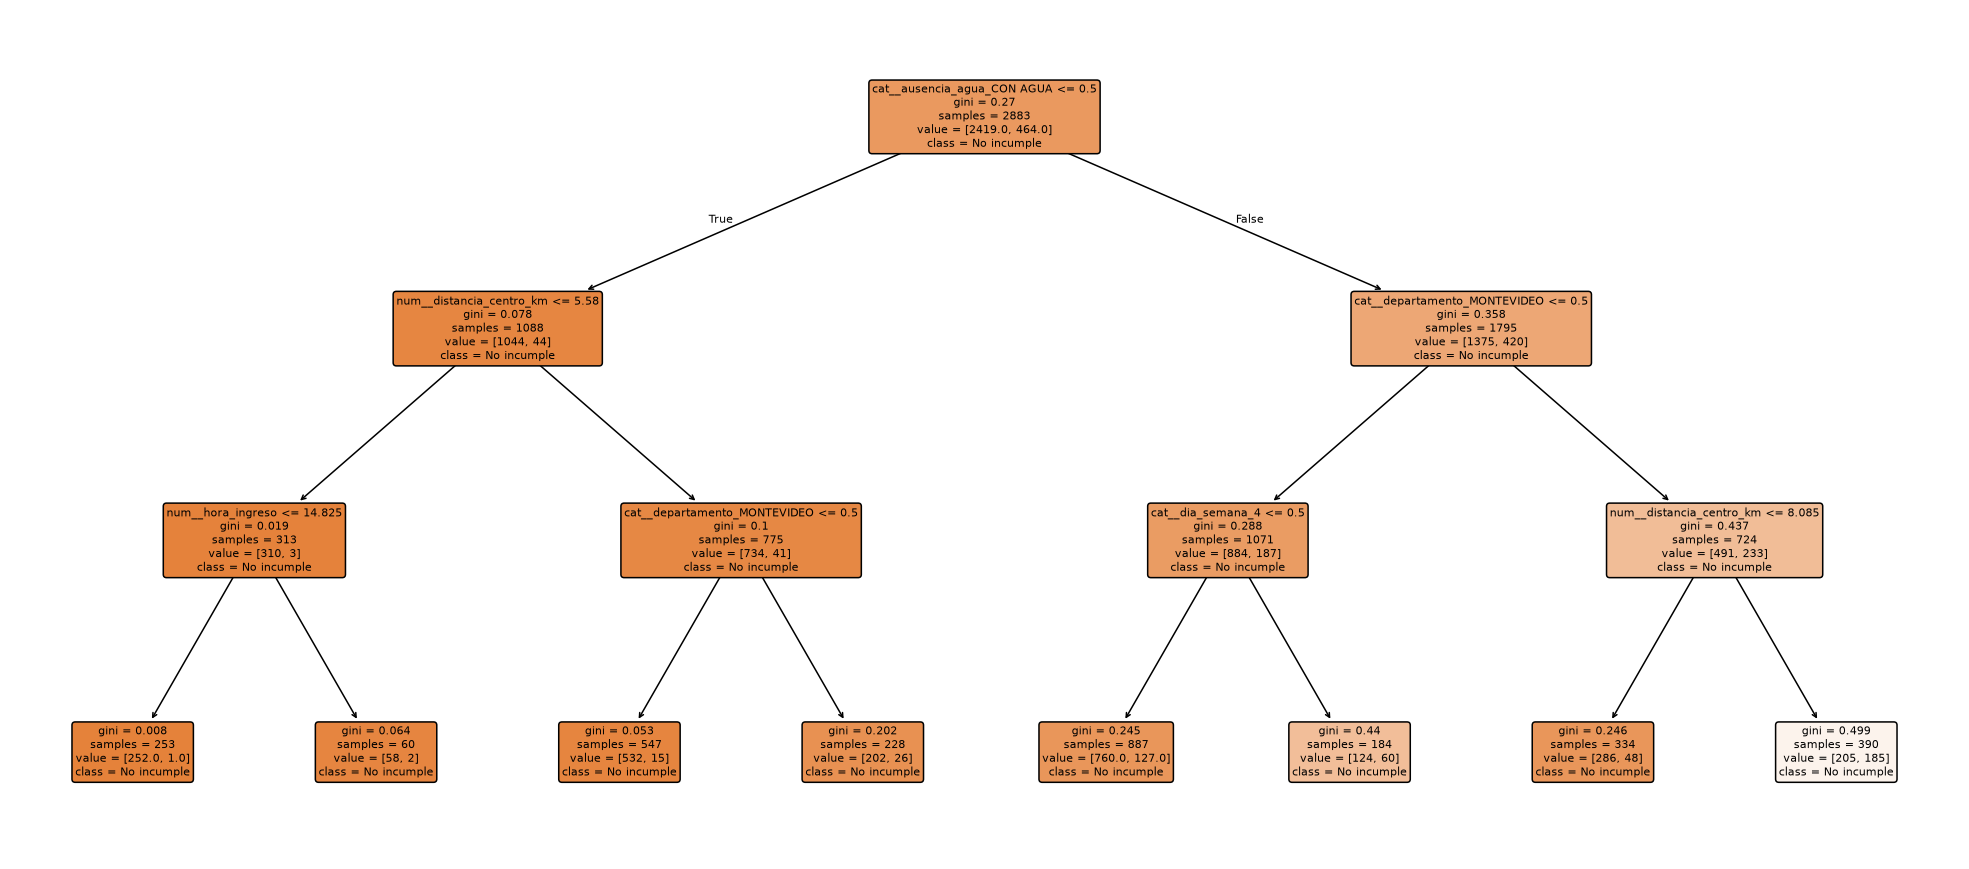

El dibujo muestra la clase mayoritaria a umbral **0,5**; por eso una hoja puede decir “No incumple” y a la vez indicar “Priorizar” en la tabla económica. La acción usa el umbral **0,143** derivado en sección 9. No son decisiones contradictorias: se declara cuál umbral se usa en cada representación.

El supervisor puede recorrer hasta tres condiciones con información de ingreso; se gana trazabilidad y rapidez de lectura, pero se pierde flexibilidad frente a la logística y las tasas de hojas pequeñas son inestables. Una hoja cercana a la prevalencia no aporta una segmentación útil aunque tenga un nombre. Las diferencias y tamaños anteriores permiten identificar esas hojas; no se presentan todas como hallazgos por el mero hecho de existir.

In [17]:
arbol_pequeno=flujo(DecisionTreeClassifier(max_depth=3,min_samples_leaf=30,random_state=SEMILLA),escalar=False)
resultado_arbol=evaluar(arbol_pequeno,X_train,yc_train,cv_clas,'clas')
resultado_arbol['resumen'].to_csv(SALIDAS/'cv_arbol_pequeno.csv')
display(pd.concat({'Base':clas_resultados['Base prevalencia']['resumen'],
    'Logística':clas_resultados['Logística']['resumen'],'Árbol pequeño':resultado_arbol['resumen']},axis=1))
display(comparar_politicas(yc_train,resultado_arbol['oof'],cv_clas))
arbol_pequeno.fit(X_train,yc_train)
pre=arbol_pequeno.named_steps['preparar']; modelo_arbol=arbol_pequeno.named_steps['modelo']
nombres_arbol=pre.get_feature_names_out(); matriz=pre.transform(X_train)
hojas=modelo_arbol.apply(matriz)
medianas=pre.named_transformers_['num'].named_steps['imputar'].statistics_
display(pd.DataFrame({'variable':NUM,'valor_si_falta':medianas}))
diccionario={'distancia_centro_km':'distancia desde el centro (km)',
    'conexiones_afectadas':'conexiones afectadas','hora_ingreso':'hora de ingreso',
    'departamento':'departamento','id_tipo_reclamo_operativo':'tipo de reclamo',
    'tipo_complejidad':'complejidad','ausencia_agua':'situación de agua',
    'baja_presion':'presión','inunda':'inundación','mes_ingreso':'mes de ingreso',
    'dia_semana':'día de semana (0=lunes, 6=domingo)'}
def condicion_operativa(feature,umbral,izquierda):
    nombre=nombres_arbol[feature]
    if nombre.startswith('num__missingindicator_'):
        original=nombre.removeprefix('num__missingindicator_')
        return ('NO falta ' if izquierda else 'FALTA ')+diccionario.get(original,original)
    if nombre.startswith('num__'):
        original=nombre.removeprefix('num__')
        return f'{diccionario.get(original,original)} {"≤" if izquierda else ">"} {umbral:.3f}'
    for c in CAT:
        prefijo='cat__'+c+'_'
        if nombre.startswith(prefijo):
            categoria=nombre.removeprefix(prefijo)
            return f'{diccionario.get(c,c)} {"no es" if izquierda else "es"} «{categoria}»'
    return f'{nombre} {"≤" if izquierda else ">"} {umbral:.3f}'

reglas=[]
def recorrer(nodo,ruta):
    t=modelo_arbol.tree_
    if t.children_left[nodo]==t.children_right[nodo]:
        mascara=hojas==nodo; n=int(mascara.sum()); tasa=float(yc_train[mascara].mean())
        reglas.append({'hoja':nodo,'regla':' Y '.join(ruta) or 'Todos los reclamos',
            'reclamos':n,'incumplen':int(yc_train[mascara].sum()),'tasa_incumplimiento':tasa,
            'prevalencia_general':float(yc_train.mean()),'diferencia_pp':100*(tasa-yc_train.mean()),
            'razon_vs_prevalencia':tasa/yc_train.mean(),
            'accion_por_costo':'Priorizar' if tasa>=UMBRAL_COSTO else 'Cola normal'})
        return
    f=t.feature[nodo]; u=t.threshold[nodo]
    recorrer(t.children_left[nodo],ruta+[condicion_operativa(f,u,True)])
    recorrer(t.children_right[nodo],ruta+[condicion_operativa(f,u,False)])
recorrer(0,[])
tabla_reglas=pd.DataFrame(reglas)
display(tabla_reglas)
for r in reglas:
    display(Markdown(f'**Hoja {r["hoja"]}:** si {r["regla"]}, entonces **{r["accion_por_costo"]}**. En desarrollo: {r["reclamos"]} reclamos, {r["tasa_incumplimiento"]:.1%} incumplen frente a {r["prevalencia_general"]:.1%} general ({r["diferencia_pp"]:+.1f} puntos). '+('Pocos casos: regla frágil.' if r['reclamos']<30 else '')))
hojas_media=tabla_reglas.loc[tabla_reglas.diferencia_pp.abs().lt(3),'hoja'].tolist()
display(Markdown(f'Las hojas **{hojas_media}** se apartan menos de 3 puntos porcentuales de la prevalencia: bajo este criterio descriptivo no constituyen segmentaciones operativas fuertes. Pueden indicar priorización por el umbral económico, pero esa acción no prueba que la regla discrimine mejor que la prevalencia.'))
fig,ax=plt.subplots(figsize=(18,8))
plot_tree(modelo_arbol,feature_names=nombres_arbol,class_names=['No incumple','Incumple'],
          filled=True,rounded=True,fontsize=7,ax=ax)
plt.tight_layout(); plt.show()
display(Markdown('El dibujo muestra la clase mayoritaria a umbral **0,5**; por eso una hoja puede decir “No incumple” y a la vez indicar “Priorizar” en la tabla económica. La acción usa el umbral **0,143** derivado en sección 9. No son decisiones contradictorias: se declara cuál umbral se usa en cada representación.'))
tabla_reglas.to_csv(SALIDAS/'reglas_arbol.csv',index=False)
display(Markdown('El supervisor puede recorrer hasta tres condiciones con información de ingreso; se gana trazabilidad y rapidez de lectura, pero se pierde flexibilidad frente a la logística y las tasas de hojas pequeñas son inestables. Una hoja cercana a la prevalencia no aporta una segmentación útil aunque tenga un nombre. Las diferencias y tamaños anteriores permiten identificar esas hojas; no se presentan todas como hallazgos por el mero hecho de existir.'))


**Profundidad elegida y por qué:** 3, máximo ocho hojas para lectura de guardia. Mínimo 30 casos por hoja fijado por soporte, sin búsqueda de desempeño.

| hoja | regla | reclamos | tasa_incumplimiento | prevalencia_general | diferencia_pp |
| --- | --- | --- | --- | --- | --- |
| 3.0000 | situación de agua no es «CON AGUA» Y distancia desde el centro (km) ≤ 5.580 Y hora de ingreso ≤ 14.825 | 253.0000 | 0.0040 | 0.1609 | -15.6991 |
| 4.0000 | situación de agua no es «CON AGUA» Y distancia desde el centro (km) ≤ 5.580 Y hora de ingreso > 14.825 | 60.0000 | 0.0333 | 0.1609 | -12.7610 |
| 6.0000 | situación de agua no es «CON AGUA» Y distancia desde el centro (km) > 5.580 Y departamento no es «MONTEVIDEO» | 547.0000 | 0.0274 | 0.1609 | -13.3521 |
| 7.0000 | situación de agua no es «CON AGUA» Y distancia desde el centro (km) > 5.580 Y departamento es «MONTEVIDEO» | 228.0000 | 0.1140 | 0.1609 | -4.6908 |
| 10.0000 | situación de agua es «CON AGUA» Y departamento no es «MONTEVIDEO» Y día de semana (0=lunes, 6=domingo) no es «4» | 887.0000 | 0.1432 | 0.1609 | -1.7764 |
| 11.0000 | situación de agua es «CON AGUA» Y departamento no es «MONTEVIDEO» Y día de semana (0=lunes, 6=domingo) es «4» | 184.0000 | 0.3261 | 0.1609 | 16.5143 |
| 13.0000 | situación de agua es «CON AGUA» Y departamento es «MONTEVIDEO» Y distancia desde el centro (km) ≤ 8.085 | 334.0000 | 0.1437 | 0.1609 | -1.7231 |
| 14.0000 | situación de agua es «CON AGUA» Y departamento es «MONTEVIDEO» Y distancia desde el centro (km) > 8.085 | 390.0000 | 0.4744 | 0.1609 | 31.3416 |

**Desempeño del árbol pequeño contra el clasificador de la sección 6:** AUC 0,758 ± 0,020 frente a logística 0,770 ± 0,027 y base 0,500. Las hojas 10 y 13 están a menos de 3 puntos de prevalencia y no son segmentaciones fuertes. Las tasas de hojas se estiman en desarrollo, no validación independiente.

**Qué se pierde y qué se gana al reemplazar el modelo por estas reglas, en términos de la operación:** supervisor recorre hasta tres condiciones con datos de ingreso; gana legibilidad y rapidez, pierde flexibilidad y estabilidad en segmentos pequeños. Se publican medianas para entradas ausentes. Dibujo usa mayoría 0,5; tabla económica usa 0,143, explicando acciones distintas.


## 12. Autocrítica del flujo

**Sin código: es texto**, y **se escribe al final, sobre el flujo propio**, releyendo lo que el grupo efectivamente hizo en las secciones anteriores.

Identificar **la decisión metodológica más frágil del propio trabajo** —una sola, elegida y argumentada—, explicar **qué la haría fallar** y qué evidencia adicional la confirmaría o la descartaría.

No se acepta una fragilidad genérica del aprendizaje automático ni una limitación abstracta del conjunto de datos. La respuesta tiene que **nombrar una decisión que el grupo tomó**, en una sección concreta, y decir **qué número del notebook cambiaría** si esa decisión estuviera mal. Tampoco cuenta una fragilidad que el propio notebook ya resolvió.

Rúbrica: identificar la falencia (2), explicar cómo afecta al modelo (2), proponer la corrección (1).

**Decisión más frágil: usar particiones aleatorias de reclamos como aproximación a reclamos futuros (secciones 2 y 7).** Después de eliminar copias exactas, todavía puede haber reclamos distintos por el mismo episodio —una rotura o corte de agua genera varios ingresos cercanos—. KFold/StratifiedKFold pueden repartirlos entre entrenamiento y validación. Las entradas comparten territorio, tipo y fecha, y el objetivo puede compartir la misma resolución. No hay un identificador de incidente que permita verificar independencia entre todos los reclamos.

Si esa independencia fuera falsa, cambiarían **ROC AUC y AP de la logística de sección 7 y los USD por reclamo/ahorro anual de sección 9**: podrían estar sobreestimando generalización y ahorro. El test aleatorio final comparte esa limitación y no la resuelve; eliminar copias exactas tampoco elimina episodios distintos relacionados.

**Corrección y evidencia:** obtener identificador de episodio o ubicación suficientemente precisa para agrupar todos los reclamos vinculados en la misma partición, y evaluar además un bloque cronológico posterior al entrenamiento. Una caída importante frente a las cifras reportadas confirmaría fragilidad de la evaluación aleatoria; estabilidad en incidentes nuevos y meses posteriores la debilitaría. Esto se propone como validación adicional, no se afirma que ya haya sido resuelto. Es una decisión concreta del notebook, no una limitación genérica de cualquier algoritmo.

**La decisión más frágil, y en qué sección se tomó:** particiones aleatorias como aproximación a futuros reclamos independientes, secciones 2 y 7.

**Qué la haría fallar, y qué número del notebook cambiaría:** diferentes reclamos del mismo incidente pueden compartir causas y resolución. Si quedan repartidos entre entrenamiento y validación, AUC/AP de sección 7 y costo/ahorro anual de sección 9 pueden ser optimistas. Test aleatorio y quitar copias exactas no resuelven esa dependencia.

**Qué evidencia adicional la confirmaría o la descartaría:** identificador de incidente/ubicación para agrupar particiones, más validación cronológica posterior. Una caída de desempeño confirmaría fragilidad; estabilidad en incidentes y períodos nuevos la debilitaría.


## 13. Conclusiones y límites

Qué se recomienda a la organización, con qué desempeño y a qué costo, **contra la línea base de la sección 3 y expresado en dinero**.

Y **qué no se puede concluir con estos datos**. Los límites tienen que ser los de este caso —los que la auditoría de la sección 1 y la evaluación de la sección 7 dejaron a la vista—, no una lista genérica de advertencias sobre el aprendizaje automático. Entre ellos, el que impone trabajar sobre un registro parcialmente construido con fines didácticos.

La recomendación se fija con el conjunto de desarrollo antes de abrir el test: se elige entre los tres regresores pedidos por RMSE de CV y se contrasta logística con umbral económico frente a la mejor política constante. No se recomienda el flujo contaminado. Se usan los datos de test una vez para comprobar la recomendación, sin ajustar modelos ni umbral según ese resultado. Las cifras de test tienen tamaño de muestra declarado; la incertidumbre entre folds de desarrollo se conserva en las tablas anteriores.

Regresor elegido en desarrollo: Lasso
Test: 721 reclamos; incumplen: 116 prevalencia: 0.1608876560332871


,MAE_h,RMSE_h,R2
Base media,82.9451,217.9373,-0.0000
Lasso,78.6970,204.6999,0.1178


,ROC_AUC,AP,Brier,accuracy,balanced_accuracy,precision,recall,F1,costo_USD
"Base prevalencia (0,5)",0.5000,0.1609,0.1350,0.8391,0.5000,0.0000,0.0000,0.0000,43.4397
"Logística (0,5)",0.7841,0.4218,0.1137,0.8502,0.5554,0.7000,0.1207,0.2059,38.5714
Logística (costos),0.7841,0.4218,0.1137,0.6588,0.7131,0.2930,0.7931,0.4279,22.8433


,TN,FP,FN,TP,priorizados_pct,USD_por_reclamo,USD_anuales
politica,,,,,,,
Umbral por costos,383,222,24,92,43.5506,22.8433,"8,908,876.5603"
"Umbral 0,5",599,6,102,14,2.7739,38.5714,"15,042,857.1429"
Priorizar todos,0,605,0,116,100.0000,37.7601,"14,726,421.6366"
No priorizar ninguno,605,0,116,0,0.0000,43.4397,"16,941,470.1803"


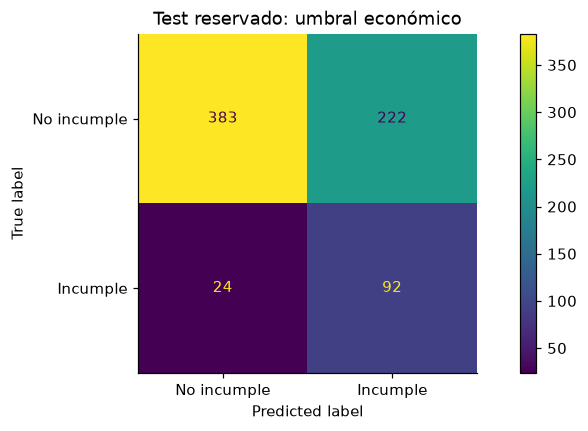

**Recomendación fijada en desarrollo:** Logística con umbral económico. La logística honesta obtiene ROC AUC de CV 0.770 ± 0.027; la base obtiene 0.500 ± 0.000.

En el test de 721 reclamos, logística con umbral 0.143 cuesta **USD 22.84 por reclamo**, proyectados a **USD 8,908,877 anuales**. Frente a la política constante elegida en desarrollo (Priorizar todos), la diferencia es **USD +14.92 por reclamo**, o **USD +5,817,545 anuales de ahorro estimado**. El signo negativo indicaría mayor costo. Estos números son una proyección condicionada al caso, no ahorro observado en OSE.

Para tiempo, Lasso tiene MAE de test **78.70 h**, frente a **82.95 h** de la base; RMSE **204.70 h**, frente a **217.94 h**. La comparación en horas permite juzgar si sirve para planificación; no basta un R². Una mejor RMSE junto con MAE peor refleja el compromiso entre cola y caso típico.


Resultados guardados en: C:\Users\marco\Downloads\OSE-proyecto\repo-grupo\resultados


In [18]:
nombre_reg_elegido=min(['Lineal','Ridge','Lasso'],key=lambda n:reg_resultados[n]['resumen'].loc['RMSE_h','media'])
modelos_reg={'Lineal':lineal,'Ridge':ridge,'Lasso':lasso}
reg_final=clone(modelos_reg[nombre_reg_elegido]).fit(X_train,yr_train)
base_r_final=clone(base_r).fit(X_train,yr_train)
log_final=clone(logistica).fit(X_train,yc_train)
base_c_final=clone(base_c).fit(X_train,yc_train)
pred_reg_test=reg_final.predict(X_test)
prob_test=log_final.predict_proba(X_test)[:,1]
prob_base_test=base_c_final.predict_proba(X_test)[:,1]
test_reg=pd.DataFrame({'Base media':metricas_reg(yr_test,base_r_final.predict(X_test)),
    nombre_reg_elegido:metricas_reg(yr_test,pred_reg_test)}).T
test_clas=pd.DataFrame({'Base prevalencia (0,5)':metricas_clas(yc_test,prob_base_test),
    'Logística (0,5)':metricas_clas(yc_test,prob_test),
    'Logística (costos)':metricas_clas(yc_test,prob_test,UMBRAL_COSTO)}).T
politicas_test=comparar_politicas(yc_test,prob_test)
print('Regresor elegido en desarrollo:',nombre_reg_elegido)
print('Test:',len(X_test),'reclamos; incumplen:',int(yc_test.sum()),'prevalencia:',yc_test.mean())
display(test_reg); display(test_clas); display(politicas_test)
ConfusionMatrixDisplay.from_predictions(yc_test,prob_test>=UMBRAL_COSTO,
    display_labels=['No incumple','Incumple']); plt.title('Test reservado: umbral económico'); plt.show()
ahorro_test=politicas_test.loc[base_politica,'USD_por_reclamo']-politicas_test.loc['Umbral por costos','USD_por_reclamo']
recomendacion='Logística con umbral económico' if ahorro_cv>0 else base_politica
display(Markdown(f"""**Recomendación fijada en desarrollo:** {recomendacion}. La logística honesta obtiene ROC AUC de CV {clas_resultados['Logística']['resumen'].loc['ROC_AUC','media']:.3f} ± {clas_resultados['Logística']['resumen'].loc['ROC_AUC','desvio']:.3f}; la base obtiene {clas_resultados['Base prevalencia']['resumen'].loc['ROC_AUC','media']:.3f} ± {clas_resultados['Base prevalencia']['resumen'].loc['ROC_AUC','desvio']:.3f}.

En el test de {len(X_test)} reclamos, logística con umbral {UMBRAL_COSTO:.3f} cuesta **USD {politicas_test.loc['Umbral por costos','USD_por_reclamo']:.2f} por reclamo**, proyectados a **USD {politicas_test.loc['Umbral por costos','USD_anuales']:,.0f} anuales**. Frente a la política constante elegida en desarrollo ({base_politica}), la diferencia es **USD {ahorro_test:+.2f} por reclamo**, o **USD {ahorro_test*VOLUMEN_ANUAL:+,.0f} anuales de ahorro estimado**. El signo negativo indicaría mayor costo. Estos números son una proyección condicionada al caso, no ahorro observado en OSE.

Para tiempo, {nombre_reg_elegido} tiene MAE de test **{test_reg.loc[nombre_reg_elegido,'MAE_h']:.2f} h**, frente a **{test_reg.loc['Base media','MAE_h']:.2f} h** de la base; RMSE **{test_reg.loc[nombre_reg_elegido,'RMSE_h']:.2f} h**, frente a **{test_reg.loc['Base media','RMSE_h']:.2f} h**. La comparación en horas permite juzgar si sirve para planificación; no basta un R². Una mejor RMSE junto con MAE peor refleja el compromiso entre cola y caso típico.
"""))
test_reg.to_csv(SALIDAS/'test_regresion.csv')
test_clas.to_csv(SALIDAS/'test_clasificacion.csv')
politicas_test.to_csv(SALIDAS/'politicas_costos_test.csv')
resumen_final={'n_ose':len(ose),'n_complemento':len(complemento),'n_final':len(datos),
    'n_desarrollo':len(X_train),'n_test':len(X_test),'negativos':int(tiempos_negativos.sum()),
    'duplicados':int(duplicados.sum()),'distancias_invalidas':int(distancias_invalidas.sum()),
    'prevalencia':float(yc.mean()),'umbral':UMBRAL_COSTO,'regresor':nombre_reg_elegido,
    'alpha_ridge':float(ridge_busqueda.best_params_['modelo__alpha']),
    'alpha_lasso':float(lasso_busqueda.best_params_['modelo__alpha']),
    'lasso_coef_cero':anulados,'brecha_auc':float(brecha_auc),
    'ahorro_anual_cv':float(ahorro_cv*VOLUMEN_ANUAL),'ahorro_anual_test':float(ahorro_test*VOLUMEN_ANUAL),
    'recomendacion':recomendacion}
(SALIDAS/'resumen.json').write_text(json.dumps(resumen_final,ensure_ascii=False,indent=2),encoding='utf-8')
print('Resultados guardados en:',SALIDAS)


**Límites específicos observados:**

1. Las tres columnas del complemento son didácticas. Su relación con demora o encuesta puede haber sido diseñada. **No se diagnostica la gestión del organismo.**
2. Se excluyen tiempos negativos/desconocidos y copias bajo un criterio explícito; se informa cuántos. El riesgo y costo estimados corresponden a los reclamos con objetivo válido, no se conocen los resultados verdaderos de los excluidos.
3. La hipótesis de representatividad del subconjunto y de independencia entre reclamos no está garantizada. El archivo anual incorpora resoluciones de reclamos anteriores; en este complemento la auditoría verifica el año de ingreso. No se extrapola sin reservas a toda la población anual.
4. La cola larga, los residuos, los posibles tiempos cero y las predicciones negativas revelan límites del regresor lineal. Las métricas en horas y su dispersión permiten verlos; no se ocultan por eliminar extremos válidos.
5. MCAR/MAR/MNAR no son plenamente identificables con el registro observado. La imputación conserva casos pero no reconstruye verdad ni elimina sesgo de selección.
6. La proyección a 390.000 usa solo USD 45/270 del ejercicio, no costo de todas las salidas ni capacidad de cuadrillas. Tampoco estima el efecto causal de priorizar sobre el tiempo; haría falta una evaluación prospectiva de la política.
7. La CV de modelos ajustados comparte folds de selección de hiperparámetros (sin CV anidada, conforme al alcance). El test se mantuvo reservado para estimar el resultado de la elección, pero es aleatorio y comparte la fragilidad temporal/de episodios señalada en sección 12.
8. Se adopta un corte fijo de plausibilidad en distancia sin confirmación de su unidad original en los valores corruptos. No se atribuye a OSE: esa columna es construida por la cátedra. La comparación de imputaciones cuantifica una sensibilidad parcial, no verifica la causa de la corrupción.

**Reproducibilidad y entrega:** conservar `data/` junto al notebook, instalar `requirements.txt`, reiniciar kernel y ejecutar todas las celdas. Entregar el notebook ejecutado por Moodle según el README de la cátedra; subir a GitHub no reemplaza esa entrega. No se agregaron familias fuera de alcance ni despliegue.


**Recomendación, con su desempeño y su costo:** logística honesta con umbral económico como política a estudiar. En test reservado: AUC 0,784, detecta 92 de 116 incumplimientos; costo USD 22,84/reclamo frente a USD 37,76 de priorizar todos y USD 43,44 de no priorizar. Proyección de USD 8,91 millones/año, con ahorro estimado USD 5,82 millones frente a la política constante elegida en desarrollo. Las cifras de CV con desvío aparecen antes; estas son resultados puntuales sobre 721 reclamos de test.

Para horas, Lasso fue elegido por RMSE de desarrollo; MAE de test 78,70 h frente a 82,95 h de base y RMSE 204,70 h frente a 217,94 h. Mejora limitada y CV variable; no es predicción individual precisa.

**Qué no se puede concluir con estos datos:** no se demuestra ahorro causal, presupuesto total ni capacidad de cuadrillas; no se garantizan representatividad, independencia de incidentes ni validez de objetivos excluidos. Mecanismos de faltantes no identificados; corte de distancia requiere confirmación. Las columnas del complemento son didácticas: **no es diagnóstico sobre gestión de OSE**. Los límites detallados se explican a continuación.
